# TESS Provenance Sigma-Clipping Controlled Experiment

This notebook applies the original iterative 5σ clipping procedure to locally cached TESSCut FITS and compares official, unclipped-TESSCut and clipped-TESSCut models on identical eligible stars and one shared stratified seed-42 split. No acquisition or external-service query is run.

Run corrected notebook 02 first. Both baseline representations must have successful extraction and at least 100 valid cadences. The processed representation must also be eligible; any additional exclusions are applied to all three model arms before splitting and recorded in an audit. FAP uses the periodogram search bounds and samples per peak. The prespecified 39 predictors are frozen across notebooks 03–08.

Fresh local preprocessing is enabled by default. Saved feature reuse requires the corrected scientific version and matching input, configuration and output hashes. Historical outputs and numerical conclusions have been cleared and must be regenerated.


## 1. Imports and configuration

The sigma-clipping intervention uses:

- **5σ** threshold;
- median center;
- standard-deviation spread;
- maximum **4 iterations**;
- early termination when an iteration removes no points.

No conditional detrending is introduced, so sigma clipping is the only preprocessing intervention relative to the original controlled provenance comparison.


In [1]:
from __future__ import annotations

import logging
import json
import tess_research_validation as trv
import os
import re
from concurrent.futures import ThreadPoolExecutor, as_completed
from pathlib import Path
from typing import Any, Dict, Optional, Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import lightkurve as lk
from astropy.io import fits
from astropy.timeseries import LombScargle
from scipy.stats import skew, kurtosis, spearmanr

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    accuracy_score,
    balanced_accuracy_score,
)
from sklearn.inspection import permutation_importance

from IPython.display import display

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 220)

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s %(levelname)s:%(name)s:%(message)s",
)
Logger = logging.getLogger("SigmaClippingProvenanceExperiment")

# ----------------------------
# Project configuration
# ----------------------------
Project_Root = Path(
    os.environ.get("Project_Root", "/data/projects/TESS_Research_Publication")
)

RUN_SIGMA_CLIPPING_FROM_FITS = True

# ----------------------------
# Controlled metadata inputs
# ----------------------------
RawDataRoot = Project_Root / "data"

SPOC_TESSCut_Consolided_Meta = (
    Project_Root
    / "data"
    / "SPOC_TESSCutCache"
    / "SPOC_TESSCut_Metadata_Consolidated_QC.parquet"
)

QLP_TESSCut_Consolided_Meta = (
    Project_Root
    / "data"
    / "QLP_TESSCutCache"
    / "QLP_TESSCut_Metadata_Consolidated_QC.parquet"
)

# Existing old feature tables used by Steps 21–22.
SPOC_TESSCut_OldFeatures = (
    Project_Root
    / "data"
    / "SPOC_TESSCutCache"
    / "SPOC_TESSCut_features_QC.parquet"
)

QLP_TESSCut_OldFeatures = (
    Project_Root
    / "data"
    / "QLP_TESSCutCache"
    / "QLP_TESSCut_features_QC.parquet"
)

# New outputs.
OutputDir = Project_Root / "results" / "sigma_clipping"
OutputDir.mkdir(parents=True, exist_ok=True)

SPOC_TESSCut_ClippedFeatures = (
    OutputDir / "SPOC_TESSCut_features_sigma_clipped.parquet"
)
QLP_TESSCut_ClippedFeatures = (
    OutputDir / "QLP_TESSCut_features_sigma_clipped.parquet"
)

# FeatureExtractor_consolidated settings.
MinPeriodDays = 0.05
MaxPeriodDays = 100.0
SamplesPerPeak = 10
MinCadences = 100
PhaseBinCount = 20
WorkerCount = 24
SigmaClipWorkerCount = 24
Eps = 1e-12

# Sigma-clipping intervention.
SigmaClipSigma = 5.0
SigmaClipMaxIterations = 4
ClipOnlyProvenance = "TESSCut"

# Step 21–23 RF settings.
TargetColumn = "family"
RandomState = 42
TestSize = 0.30
PermutationRepeats = 50

QualityScoreMap = {
    "clean": 0,
    "acceptable": 1,
    "caution": 2,
    "poor": 3,
    "missing": 4,
}

ProvenanceScoreMap = {
    "SPOC": 0,
    "QLP": 1,
    "TESSCut": 2,
}

print("SPOC–TESSCut metadata:", SPOC_TESSCut_Consolided_Meta)
print("QLP–TESSCut metadata: ", QLP_TESSCut_Consolided_Meta)
print(
    f"Sigma clipping: {SigmaClipSigma:.1f}σ, "
    f"max iterations={SigmaClipMaxIterations}"
)
# False is opt-in reuse of a hash-validated corrected feature cache only.
SIGMA_FEATURE_CONFIG = {
    'experiment': 'sigma_clipping', 'science_fix_version': trv.SCIENCE_FIX_VERSION,
    'features': list(trv.FEATURE_COLUMNS), 'minimum_cadences': MinCadences,
    'ls_min_period_days': MinPeriodDays, 'ls_max_period_days': MaxPeriodDays,
    'ls_samples_per_peak': SamplesPerPeak, 'ls_fap_method': 'baluev',
    'fap_policy': 'periodogram_search_bounds',
    'sigma': SigmaClipSigma, 'maximum_iterations': SigmaClipMaxIterations,
    'center': 'median', 'spread': 'standard_deviation',
}
BASELINE_PATHS = {'SPOC': SPOC_TESSCut_OldFeatures, 'QLP': QLP_TESSCut_OldFeatures}
METADATA_PATHS = {'SPOC': SPOC_TESSCut_Consolided_Meta, 'QLP': QLP_TESSCut_Consolided_Meta}


SPOC–TESSCut metadata: /data/projects/TESS_Research_Publication/data/SPOC_TESSCutCache/SPOC_TESSCut_Metadata_Consolidated_QC.parquet
QLP–TESSCut metadata:  /data/projects/TESS_Research_Publication/data/QLP_TESSCutCache/QLP_TESSCut_Metadata_Consolidated_QC.parquet
Sigma clipping: 5.0σ, max iterations=4


## 2. Read and validate the two consolidated control metadata tables

In [2]:
def NormalizeProvenanceLabel(Value):
    if pd.isna(Value):
        return "Missing"

    Text = str(Value).strip()
    Upper = Text.upper()

    if Upper == "SPOC":
        return "SPOC"
    if Upper == "QLP":
        return "QLP"
    if Upper in {"TESSCUT", "TESS CUT"}:
        return "TESSCut"

    return Text


def ResolveProvenanceColumn(Df):
    for ColumnName in [
        "Provenance",
        "provenance",
        "Source",
        "source",
        "author",
    ]:
        if ColumnName in Df.columns:
            return ColumnName
    raise KeyError("Could not find a provenance/source column.")


def ValidateMetadata(Df, Label):
    Required = {"VSXId", TargetColumn, "lightCurvePath"}
    Missing = sorted(Required - set(Df.columns))

    if Missing:
        raise ValueError(
            f"{Label}: missing required metadata columns: {Missing}"
        )

    return ResolveProvenanceColumn(Df)


SpocMetaDf = pd.read_parquet(SPOC_TESSCut_Consolided_Meta)
QlpMetaDf = pd.read_parquet(QLP_TESSCut_Consolided_Meta)

SpocMetaProvenanceColumn = ValidateMetadata(
    SpocMetaDf,
    "SPOC–TESSCut",
)
QlpMetaProvenanceColumn = ValidateMetadata(
    QlpMetaDf,
    "QLP–TESSCut",
)

for Label, Df, ProvenanceColumn in [
    ("SPOC–TESSCut", SpocMetaDf, SpocMetaProvenanceColumn),
    ("QLP–TESSCut", QlpMetaDf, QlpMetaProvenanceColumn),
]:
    print(f"\n{Label}: {len(Df):,} metadata rows")
    display(
        Df[ProvenanceColumn]
        .map(NormalizeProvenanceLabel)
        .value_counts(dropna=False)
        .rename_axis("Provenance")
        .reset_index(name="Rows")
    )
# Require corrected, eligible paired features before processing any FITS.
BASELINE_IDS = {}
for name, variable in [('SPOC', 'SpocMetaDf'), ('QLP', 'QlpMetaDf')]:
    baseline = trv.read_corrected_features(BASELINE_PATHS[name])
    trv.require_feature_schema(baseline)
    baseline = trv.eligible_rows(baseline, MinCadences)
    baseline['VSXId'] = baseline['VSXId'].astype(str)
    baseline['_Provenance'] = baseline[ResolveProvenanceColumn(baseline)].map(NormalizeProvenanceLabel)
    sides = {}
    for side in [name, 'TESSCut']:
        rows = baseline[baseline['_Provenance'].eq(side)].copy()
        counts = rows.groupby('VSXId').size()
        sides[side] = rows[rows['VSXId'].isin(counts.index[counts.eq(1)])].set_index('VSXId', drop=False).sort_index()
    ids = sides[name].index.intersection(sides['TESSCut'].index).sort_values()
    if not sides[name].loc[ids, TargetColumn].astype(str).equals(sides['TESSCut'].loc[ids, TargetColumn].astype(str)):
        raise ValueError(f'{name}: baseline family labels disagree')
    counts = sides[name].loc[ids, TargetColumn].astype(str).value_counts()
    ids = ids[sides[name].loc[ids, TargetColumn].astype(str).isin(counts[counts >= 2].index)]
    if len(ids) == 0:
        raise ValueError(f'{name}: no eligible matched baseline stars')
    BASELINE_IDS[name] = ids.tolist()
    meta = globals()[variable].copy()
    meta['VSXId'] = meta['VSXId'].astype(str)
    meta['_Provenance'] = meta[ResolveProvenanceColumn(meta)].map(NormalizeProvenanceLabel)
    meta = meta[meta['VSXId'].isin(ids) & meta['_Provenance'].isin([name, 'TESSCut'])].copy()
    counts = meta.groupby(['VSXId', '_Provenance']).size().unstack(fill_value=0)
    if not counts.reindex(index=ids, columns=[name, 'TESSCut'], fill_value=0).eq(1).all().all():
        raise ValueError(f'{name}: metadata must have exactly one row per baseline representation')
    for side in [name, 'TESSCut']:
        labels = meta[meta['_Provenance'].eq(side)].set_index('VSXId').loc[ids, TargetColumn].astype(str)
        if not labels.equals(sides[name].loc[ids, TargetColumn].astype(str)):
            raise ValueError(f'{name}: metadata labels differ from corrected baseline')
    globals()[variable] = meta.drop(columns=['_Provenance'])
    pd.DataFrame({'VSXId': ids, TargetColumn: sides[name].loc[ids, TargetColumn].astype(str).to_numpy()}).to_csv(OutputDir / f'{name}_eligible_baseline_ids.csv', index=False)
    print(name, 'eligible matched baseline stars:', len(ids))



SPOC–TESSCut: 1,012 metadata rows


,Provenance,Rows
0,SPOC,506
1,TESSCut,506



QLP–TESSCut: 2,732 metadata rows


,Provenance,Rows
0,QLP,1366
1,TESSCut,1366


SPOC eligible matched baseline stars: 506
QLP eligible matched baseline stars: 1353


## 3. Utility functions and light-curve loading

The utility and light-curve loading functions use the same logic as the consolidated feature extractor. Relative light-curve paths are resolved against the project's data-pipeline directory.


In [3]:
def SafeFloat(Value: Any) -> float:
    try:
        FloatValue = float(Value)
    except Exception:
        return np.nan
    return FloatValue if np.isfinite(FloatValue) else np.nan


def SafeBool(Value: Any) -> bool:
    if Value is None:
        return False
    if isinstance(Value, float) and pd.isna(Value):
        return False
    return bool(Value)


def SafeDivide(Numerator: float, Denominator: float, Eps: float = Eps) -> float:
    if not np.isfinite(Numerator) or not np.isfinite(Denominator) or abs(Denominator) < Eps:
        return np.nan
    return float(Numerator / Denominator)


def ResolvePath(PathValue: Any, MetadataPath: Path) -> Optional[Path]:
    if PathValue is None:
        return None
    if isinstance(PathValue, float) and pd.isna(PathValue):
        return None

    PathObj = Path(str(PathValue))
    if PathObj.is_absolute() and PathObj.exists():
        return PathObj
    if PathObj.exists():
        return PathObj

    CandidatePath = MetadataPath.parent / PathObj
    if CandidatePath.exists():
        return CandidatePath

    return PathObj

In [4]:
def ResolveExperimentLightCurvePath(PathValue):
    if PathValue is None:
        return None
    if isinstance(PathValue, float) and pd.isna(PathValue):
        return None

    PathObj = Path(str(PathValue))

    if PathObj.is_absolute():
        return PathObj

    return RawDataRoot / PathObj


def LoadLightCurve(LightCurvePath: Path) -> Tuple[np.ndarray, np.ndarray, Optional[np.ndarray]]:
    """Load a light curve while treating flux uncertainty as optional.

    Time and flux determine whether a cadence is scientifically usable.
    FluxErr is retained only when it is aligned with the loaded arrays and all
    retained uncertainty values are finite and strictly positive. Invalid or
    missing uncertainty therefore downgrades Lomb-Scargle from weighted to
    unweighted analysis instead of removing otherwise valid QLP cadences.
    """

    def FirstAvailableColumn(ColumnNames: list[str], CandidateNames: list[str]) -> Optional[str]:
        NameMap = {Name.upper(): Name for Name in ColumnNames}
        for CandidateName in CandidateNames:
            MatchedName = NameMap.get(CandidateName.upper())
            if MatchedName is not None:
                return MatchedName
        return None

    def ReadGenericFitsTable(FitsPath: Path) -> Tuple[np.ndarray, np.ndarray, Optional[np.ndarray]]:
        with fits.open(str(FitsPath), memmap=False) as Hdul:
            TableData = None

            for Hdu in Hdul:
                Data = getattr(Hdu, "data", None)
                if Data is not None and getattr(Data, "dtype", None) is not None and Data.dtype.names:
                    TableData = Data
                    break

            if TableData is None:
                raise ValueError("No FITS binary table with named columns was found")

            ColumnNames = list(TableData.dtype.names)

            TimeColumn = FirstAvailableColumn(
                ColumnNames,
                ["TIME", "TMID", "BJD"],
            )
            FluxColumn = FirstAvailableColumn(
                ColumnNames,
                ["FLUX", "SAP_FLUX", "PDCSAP_FLUX", "KSPSAP_FLUX", "DET_FLUX", "NORM_FLUX"],
            )
            FluxErrColumn = FirstAvailableColumn(
                ColumnNames,
                ["FLUX_ERR", "SAP_FLUX_ERR", "PDCSAP_FLUX_ERR", "KSPSAP_FLUX_ERR", "ERR_FLUX"],
            )

            if TimeColumn is None or FluxColumn is None:
                raise ValueError(
                    f"Required time/flux columns are missing. Available columns: {ColumnNames}"
                )

            Time = np.asarray(TableData[TimeColumn], dtype=float).reshape(-1)
            Flux = np.asarray(TableData[FluxColumn], dtype=float).reshape(-1)
            FluxErr = None

            if FluxErrColumn is not None:
                FluxErr = np.asarray(TableData[FluxErrColumn], dtype=float).reshape(-1)

            return Time, Flux, FluxErr

    def ExtractFromLightkurve(LightCurve) -> Tuple[np.ndarray, np.ndarray, Optional[np.ndarray]]:
        Time = np.asarray(
            getattr(LightCurve.time, "value", LightCurve.time),
            dtype=float,
        ).reshape(-1)

        Flux = np.asarray(
            getattr(LightCurve.flux, "value", LightCurve.flux),
            dtype=float,
        ).reshape(-1)

        FluxErr = None
        if hasattr(LightCurve, "flux_err") and LightCurve.flux_err is not None:
            FluxErr = np.asarray(
                getattr(LightCurve.flux_err, "value", LightCurve.flux_err),
                dtype=float,
            ).reshape(-1)

        return Time, Flux, FluxErr

    LightCurvePath = Path(LightCurvePath)

    if not LightCurvePath.exists():
        raise FileNotFoundError(str(LightCurvePath))

    Time = None
    Flux = None
    FluxErr = None
    ReadErrors = []

    # Attempt 1: standard lightkurve reader.
    try:
        LightCurve = lk.read(str(LightCurvePath))
        Time, Flux, FluxErr = ExtractFromLightkurve(LightCurve)
    except Exception as Exc:
        ReadErrors.append(f"generic lk.read: {Exc!r}")

    # Attempt 2: QLP-specific reader.
    if Time is None or Flux is None:
        try:
            LightCurve = lk.read(
                str(LightCurvePath),
                author="QLP",
                flux_column="kspsap_flux",
            )
            Time, Flux, FluxErr = ExtractFromLightkurve(LightCurve)
        except Exception as Exc:
            ReadErrors.append(f"QLP lk.read: {Exc!r}")

    # Attempt 3: direct FITS table parsing.
    if Time is None or Flux is None:
        try:
            Time, Flux, FluxErr = ReadGenericFitsTable(LightCurvePath)
        except Exception as Exc:
            ReadErrors.append(f"generic FITS parsing: {Exc!r}")
            raise ValueError(
                "Unable to read light curve. " + " | ".join(ReadErrors)
            ) from Exc

    if Time.shape != Flux.shape:
        raise ValueError(
            f"Time/Flux shape mismatch: Time={Time.shape}, Flux={Flux.shape}"
        )

    # Only Time and Flux define a valid cadence.
    CadenceMask = np.isfinite(Time) & np.isfinite(Flux)

    FilteredTime = Time[CadenceMask]
    FilteredFlux = Flux[CadenceMask]
    FilteredFluxErr = None

    # FluxErr is optional. It must never remove otherwise valid Time/Flux rows.
    if FluxErr is not None:
        if FluxErr.shape == Time.shape:
            CandidateFluxErr = FluxErr[CadenceMask]
            ValidFluxErr = np.isfinite(CandidateFluxErr) & (CandidateFluxErr > 0)

            if len(CandidateFluxErr) > 0 and np.all(ValidFluxErr):
                FilteredFluxErr = CandidateFluxErr
            else:
                Logger.debug(
                    "Ignoring unusable flux_err for %s: %d/%d retained values are finite and positive",
                    LightCurvePath,
                    int(np.sum(ValidFluxErr)),
                    len(CandidateFluxErr),
                )
        else:
            Logger.debug(
                "Ignoring flux_err shape mismatch for %s: flux_err=%s, time=%s",
                LightCurvePath,
                FluxErr.shape,
                Time.shape,
            )

    # Keep samples in chronological order.
    Order = np.argsort(FilteredTime)
    FilteredTime = FilteredTime[Order]
    FilteredFlux = FilteredFlux[Order]

    if FilteredFluxErr is not None:
        FilteredFluxErr = FilteredFluxErr[Order]

    return FilteredTime, FilteredFlux, FilteredFluxErr

## 4. Iterative sigma clipping

For each TESSCut light curve, every iteration computes the median \(m\) and ordinary standard deviation \(s\) of the retained flux samples and keeps cadences satisfying:

$$
|F_i - m| \le N_\sigma s
$$

The same cadence mask is applied to time and to `flux_err` when present. Iteration stops when no additional cadences are removed or after four iterations.

Only TESSCut rows are clipped. Unique TESSCut source paths are processed with `ThreadPoolExecutor`, using 24 workers by default, and repeated references to the same source file are deduplicated within each control set. Each clipped curve is saved beside its source FITS with the suffix `_TESSCut_sigma_clipped.fits`.

The experimental metadata preserves the original path in `OriginalLightCurvePath` and redirects `lightCurvePath` to the saved sigma-clipped FITS for TESSCut rows. SPOC and QLP paths remain unchanged. A clipping or write failure raises an error rather than substituting the unclipped source curve.

Because astrophysical eclipses, flares, and outbursts can also produce extreme flux values, the experiment measures the effect of this clipping rule without assigning an instrumental origin to every removed cadence.


In [5]:
def IterativeSigmaClip(
    Time,
    Flux,
    FluxErr,
    Sigma=SigmaClipSigma,
    MaxIterations=SigmaClipMaxIterations,
):
    TimeOut = np.asarray(Time, dtype=float).copy()
    FluxOut = np.asarray(Flux, dtype=float).copy()

    FluxErrOut = (
        None
        if FluxErr is None
        else np.asarray(FluxErr, dtype=float).copy()
    )

    InitialCount = len(FluxOut)
    IterationsUsed = 0
    RemovedByIteration = []

    for Iteration in range(1, MaxIterations + 1):
        if len(FluxOut) < 2:
            break

        Center = float(np.median(FluxOut))
        Spread = float(np.std(FluxOut))

        if not np.isfinite(Spread) or Spread <= Eps:
            break

        KeepMask = (
            np.abs(FluxOut - Center)
            <= Sigma * Spread
        )

        RemovedThisIteration = int(np.sum(~KeepMask))
        RemovedByIteration.append(RemovedThisIteration)
        IterationsUsed = Iteration

        if RemovedThisIteration == 0:
            break

        TimeOut = TimeOut[KeepMask]
        FluxOut = FluxOut[KeepMask]

        if FluxErrOut is not None:
            FluxErrOut = FluxErrOut[KeepMask]

    FinalCount = len(FluxOut)
    RemovedCount = InitialCount - FinalCount

    RemovedFraction = (
        RemovedCount / InitialCount
        if InitialCount > 0
        else np.nan
    )

    Diagnostics = {
        "SigmaClipApplied": True,
        "SigmaClipSigma": float(Sigma),
        "SigmaClipMaxIterations": int(MaxIterations),
        "SigmaClipIterationsUsed": int(IterationsUsed),
        "CadenceCountBeforeClip": int(InitialCount),
        "CadenceCountAfterClip": int(FinalCount),
        "ClippedCadenceCount": int(RemovedCount),
        "ClippedCadenceFraction": float(RemovedFraction),
        "SigmaClipRemovedByIteration": ",".join(
            str(Value)
            for Value in RemovedByIteration
        ),
    }

    return TimeOut, FluxOut, FluxErrOut, Diagnostics

## 5. Multithreaded TESSCut sigma-clipping preprocessing

This stage performs the sigma-clipping intervention across multiple TESSCut light curves in parallel and saves the resulting clipped FITS files before any features are extracted.

The feature-extraction stage below therefore reads the saved clipped light curves from disk; it does **not** clip them a second time.

In [6]:

def BuildSigmaClippedLightCurvePath(SourcePath: Path) -> Path:
    """Return a same-folder path ending in *_TESSCut_sigma_clipped.fits."""
    SourcePath = Path(SourcePath)
    Stem = SourcePath.stem

    Match = re.search(
        r"_TESSCut(?:_|$)",
        Stem,
        flags=re.IGNORECASE,
    )

    if Match is not None:
        Prefix = Stem[:Match.start()]
    else:
        Prefix = Stem

    Prefix = Prefix.rstrip("_")

    if Prefix:
        OutputName = (
            f"{Prefix}_TESSCut_sigma_clipped.fits"
        )
    else:
        OutputName = "TESSCut_sigma_clipped.fits"

    return SourcePath.with_name(OutputName)


def SaveSigmaClippedLightCurveFits(
    OutputPath: Path,
    Time: np.ndarray,
    Flux: np.ndarray,
    FluxErr: Optional[np.ndarray],
    SourcePath: Path,
    Diagnostics: Dict[str, Any],
):
    """Save the clipped arrays as a compact FITS binary table."""
    OutputPath = Path(OutputPath)
    OutputPath.parent.mkdir(
        parents=True,
        exist_ok=True,
    )

    Columns = [
        fits.Column(
            name="TIME",
            format="D",
            array=np.asarray(Time, dtype=np.float64),
        ),
        fits.Column(
            name="FLUX",
            format="D",
            array=np.asarray(Flux, dtype=np.float64),
        ),
    ]

    if FluxErr is not None:
        Columns.append(
            fits.Column(
                name="FLUX_ERR",
                format="D",
                array=np.asarray(
                    FluxErr,
                    dtype=np.float64,
                ),
            )
        )

    TableHdu = fits.BinTableHDU.from_columns(
        Columns,
        name="LIGHTCURVE",
    )

    Header = TableHdu.header
    Header["PROVEN"] = "TESSCut"
    Header["SIGCLIP"] = True
    Header["CLIPSIG"] = (
        float(Diagnostics["SigmaClipSigma"]),
        "Sigma threshold",
    )
    Header["CLIPITER"] = (
        int(Diagnostics["SigmaClipIterationsUsed"]),
        "Iterations used",
    )
    Header["NBEFORE"] = (
        int(Diagnostics["CadenceCountBeforeClip"]),
        "Cadences before clipping",
    )
    Header["NAFTER"] = (
        int(Diagnostics["CadenceCountAfterClip"]),
        "Cadences after clipping",
    )
    Header["NCLIPPED"] = (
        int(Diagnostics["ClippedCadenceCount"]),
        "Cadences removed",
    )
    Header.add_history(
        "Iterative sigma clipping applied to TESSCut light curve."
    )
    Header.add_history(
        f"Source FITS: {SourcePath}"
    )

    PrimaryHdu = fits.PrimaryHDU()

    fits.HDUList(
        [PrimaryHdu, TableHdu]
    ).writeto(
        OutputPath,
        overwrite=True,
        checksum=True,
    )


def SigmaClipAndSaveOneTessCut(SourcePath: Path):
    """Load, sigma clip, save, and return diagnostics for one unique TESSCut FITS."""
    SourcePath = Path(SourcePath)

    Time, Flux, FluxErr = LoadLightCurve(
        SourcePath
    )

    (
        ClippedTime,
        ClippedFlux,
        ClippedFluxErr,
        Diagnostics,
    ) = IterativeSigmaClip(
        Time,
        Flux,
        FluxErr,
    )

    OutputPath = BuildSigmaClippedLightCurvePath(
        SourcePath
    )

    if OutputPath.resolve() == SourcePath.resolve():
        raise ValueError(
            "Sigma-clipped output path resolves to "
            f"the source path: {SourcePath}"
        )

    SaveSigmaClippedLightCurveFits(
        OutputPath=OutputPath,
        Time=ClippedTime,
        Flux=ClippedFlux,
        FluxErr=ClippedFluxErr,
        SourcePath=SourcePath,
        Diagnostics=Diagnostics,
    )

    return {
        "SourcePath": str(SourcePath),
        "SigmaClippedPath": str(OutputPath),
        **Diagnostics,
        "SigmaClipWriteStatus": "ok",
        "SigmaClipWriteError": None,
    }


def SigmaClipTessCutMetadataParallel(
    MetadataDf: pd.DataFrame,
    WorkerCountValue: int = SigmaClipWorkerCount,
):
    """Clip/save all unique TESSCut files in parallel and redirect metadata paths."""
    ResultDf = MetadataDf.copy()

    ProvenanceColumn = ResolveProvenanceColumn(
        ResultDf
    )

    ResultDf["OriginalLightCurvePath"] = (
        ResultDf["lightCurvePath"]
    )

    DefaultDiagnostics = {
        "SigmaClipApplied": False,
        "SigmaClipSigma": float(SigmaClipSigma),
        "SigmaClipMaxIterations": int(
            SigmaClipMaxIterations
        ),
        "SigmaClipIterationsUsed": 0,
        "CadenceCountBeforeClip": np.nan,
        "CadenceCountAfterClip": np.nan,
        "ClippedCadenceCount": 0,
        "ClippedCadenceFraction": 0.0,
        "SigmaClipRemovedByIteration": "",
        "SigmaClippedLightCurvePath": None,
        "SigmaClipWriteStatus": "not_applicable",
        "SigmaClipWriteError": None,
    }

    for ColumnName, DefaultValue in (
        DefaultDiagnostics.items()
    ):
        ResultDf[ColumnName] = DefaultValue

    TessMask = (
        ResultDf[ProvenanceColumn]
        .map(NormalizeProvenanceLabel)
        == ClipOnlyProvenance
    )

    TessRows = ResultDf.loc[
        TessMask
    ].copy()

    if TessRows.empty:
        Logger.warning(
            "No TESSCut rows found for sigma clipping."
        )
        return ResultDf, pd.DataFrame()

    # Resolve and deduplicate source paths.
    ResolvedSourceByRow = {}

    for RowIndex, Row in TessRows.iterrows():
        SourcePath = ResolveExperimentLightCurvePath(
            Row.get("lightCurvePath")
        )

        if SourcePath is None:
            raise ValueError(
                f"TESSCut row {RowIndex} has no lightCurvePath."
            )

        SourcePath = Path(SourcePath)

        if not SourcePath.exists():
            raise FileNotFoundError(
                f"TESSCut source FITS does not exist: {SourcePath}"
            )

        ResolvedSourceByRow[
            RowIndex
        ] = str(SourcePath.resolve())

    UniqueSourcePaths = sorted(
        set(ResolvedSourceByRow.values())
    )

    Logger.info(
        "Sigma clipping %s unique TESSCut curves "
        "with %s workers",
        len(UniqueSourcePaths),
        WorkerCountValue,
    )

    ResultsBySource = {}

    with ThreadPoolExecutor(
        max_workers=WorkerCountValue
    ) as Executor:
        FutureMap = {
            Executor.submit(
                SigmaClipAndSaveOneTessCut,
                Path(SourcePath),
            ): SourcePath
            for SourcePath in UniqueSourcePaths
        }

        CompletedCount = 0

        for Future in as_completed(FutureMap):
            SourcePath = FutureMap[Future]

            try:
                ClipResult = Future.result()
            except Exception as Exc:
                ClipResult = {
                    "SourcePath": SourcePath,
                    "SigmaClippedPath": None,
                    "SigmaClipWriteStatus": "failed",
                    "SigmaClipWriteError": repr(Exc),
                }

            ResultsBySource[
                SourcePath
            ] = ClipResult

            CompletedCount += 1

            if (
                CompletedCount % 50 == 0
                or CompletedCount
                == len(UniqueSourcePaths)
            ):
                Logger.info(
                    "Sigma clipping completed %s/%s",
                    CompletedCount,
                    len(UniqueSourcePaths),
                )

    FailedResults = [
        Result
        for Result in ResultsBySource.values()
        if Result.get("SigmaClipWriteStatus")
        != "ok"
    ]

    if FailedResults:
        FailurePreview = "\n".join(
            f"- {Item.get('SourcePath')}: "
            f"{Item.get('SigmaClipWriteError')}"
            for Item in FailedResults[:10]
        )
        raise RuntimeError(
            "One or more TESSCut sigma-clipping jobs failed. "
            "Feature extraction will not continue.\n"
            + FailurePreview
        )

    # Redirect every TESSCut metadata row to its saved clipped FITS.
    DiagnosticColumns = [
        "SigmaClipApplied",
        "SigmaClipSigma",
        "SigmaClipMaxIterations",
        "SigmaClipIterationsUsed",
        "CadenceCountBeforeClip",
        "CadenceCountAfterClip",
        "ClippedCadenceCount",
        "ClippedCadenceFraction",
        "SigmaClipRemovedByIteration",
        "SigmaClipWriteStatus",
        "SigmaClipWriteError",
    ]

    for RowIndex, ResolvedSource in (
        ResolvedSourceByRow.items()
    ):
        ClipResult = ResultsBySource[
            ResolvedSource
        ]

        ResultDf.at[
            RowIndex,
            "lightCurvePath",
        ] = ClipResult[
            "SigmaClippedPath"
        ]

        ResultDf.at[
            RowIndex,
            "SigmaClippedLightCurvePath",
        ] = ClipResult[
            "SigmaClippedPath"
        ]

        for ColumnName in DiagnosticColumns:
            if ColumnName in ClipResult:
                ResultDf.at[
                    RowIndex,
                    ColumnName,
                ] = ClipResult[
                    ColumnName
                ]

    SummaryDf = pd.DataFrame(
        list(ResultsBySource.values())
    ).sort_values(
        "SourcePath"
    ).reset_index(
        drop=True
    )

    return ResultDf, SummaryDf

if RUN_SIGMA_CLIPPING_FROM_FITS:
    SpocSigmaClipMetaDf, SpocSigmaClipFileSummaryDf = (
        SigmaClipTessCutMetadataParallel(
            SpocMetaDf,
            WorkerCountValue=SigmaClipWorkerCount,
        )
    )

    QlpSigmaClipMetaDf, QlpSigmaClipFileSummaryDf = (
        SigmaClipTessCutMetadataParallel(
            QlpMetaDf,
            WorkerCountValue=SigmaClipWorkerCount,
        )
    )

    # Save the redirected experimental metadata for reproducibility.
    SpocSigmaClipMetaPath = (
        OutputDir
        / "SPOC_TESSCut_Metadata_sigma_clipped.parquet"
    )
    QlpSigmaClipMetaPath = (
        OutputDir
        / "QLP_TESSCut_Metadata_sigma_clipped.parquet"
    )

    SpocSigmaClipMetaDf.to_parquet(
        SpocSigmaClipMetaPath,
        index=False,
    )
    QlpSigmaClipMetaDf.to_parquet(
        QlpSigmaClipMetaPath,
        index=False,
    )

    print(
        "Saved redirected SPOC–TESSCut metadata:",
        SpocSigmaClipMetaPath,
    )
    print(
        "Saved redirected QLP–TESSCut metadata:",
        QlpSigmaClipMetaPath,
    )

    print(
        f"\nSPOC-control unique TESSCut curves clipped: "
        f"{len(SpocSigmaClipFileSummaryDf):,}"
    )
    print(
        f"QLP-control unique TESSCut curves clipped: "
        f"{len(QlpSigmaClipFileSummaryDf):,}"
    )
else:
    print(
        "Sigma clipping and FITS writing skipped. "
        "Saved clipped features will be loaded in Section 8."
    )


2026-11-07 00:16:00,627 INFO:SigmaClippingProvenanceExperiment:Sigma clipping 506 unique TESSCut curves with 24 workers
2026-11-07 00:16:00,666 WARNING:astropy:UnitsWarning: 'btjd' did not parse as fits unit: At col 0, Unit 'btjd' not supported by the FITS standard.  If this is meant to be a custom unit, define it with 'u.def_unit'. To have it recognized inside a file reader or other code, enable it with 'u.add_enabled_units'. For details, see https://docs.astropy.org/en/latest/units/combining_and_defining.html


0% (0/1086) of the cadences will be ignored due to the quality mask (quality_bitmask=17087).
2026-11-07 00:16:00,829 INFO:lightkurve.utils:0% (0/1086) of the cadences will be ignored due to the quality mask (quality_bitmask=17087).
0% (0/1086) of the cadences will be ignored due to the quality mask (quality_bitmask=17087).
2026-11-07 00:16:00,850 INFO:lightkurve.utils:0% (0/1086) of the cadences will be ignored due to the quality mask (quality_bitmask=17087).
0% (0/6597) of the cadences will be ignored due to the quality mask (quality_bitmask=17087).
2026-11-07 00:16:00,866 INFO:lightkurve.utils:0% (0/6597) of the cadences will be ignored due to the quality mask (quality_bitmask=17087).
0% (0/4765) of the cadences will be ignored due to the quality mask (quality_bitmask=17087).
2026-11-07 00:16:00,901 INFO:lightkurve.utils:0% (0/4765) of the cadences will be ignored due to the quality mask (quality_bitmask=17087).
0% (0/9360) of the cadences will be ignored due to the quality mask (qua

Saved redirected SPOC–TESSCut metadata: /data/projects/TESS_Research_Publication/results/sigma_clipping/SPOC_TESSCut_Metadata_sigma_clipped.parquet
Saved redirected QLP–TESSCut metadata: /data/projects/TESS_Research_Publication/results/sigma_clipping/QLP_TESSCut_Metadata_sigma_clipped.parquet

SPOC-control unique TESSCut curves clipped: 506
QLP-control unique TESSCut curves clipped: 1,353


## 6. Feature definitions

The next cells are copied from the authoritative `FeatureExtractor_consolidated_2026_08_07_output_v2` source so the intervention changes the light-curve samples, not the feature definitions.

In [7]:
def ExtractIdentifierAndMetadataFeatures(Row: pd.Series) -> Dict[str, Any]:
    Result: Dict[str, Any] = {}

    ColumnsToPreserve = [
        "family", "VSXType", "VSXId", "Name", "ticId", "bestTicId",
        "ticDistanceArcmin", "lightCurvePath", "rawLightCurvePath",
        "trendFlag", "trendScore", "adfPValue",
        "OriginalLightCurvePath",
        "SigmaClippedLightCurvePath",
        "SigmaClipApplied",
        "SigmaClipSigma",
        "SigmaClipMaxIterations",
        "SigmaClipIterationsUsed",
        "CadenceCountBeforeClip",
        "CadenceCountAfterClip",
        "ClippedCadenceCount",
        "ClippedCadenceFraction",
        "SigmaClipRemovedByIteration",
        "SigmaClipWriteStatus",
        "SigmaClipWriteError",
    ]

    for ColumnName in ColumnsToPreserve:
        if ColumnName in Row.index:
            Result[ColumnName] = Row.get(ColumnName)

    QualityValue = Row.get("quality", Row.get("fitsQcStatus", Row.get("lightCurveQuality", np.nan)))
    ProvenanceValue = Row.get("provenance", Row.get("author", np.nan))

    QualityLabel = str(QualityValue) if not pd.isna(QualityValue) else "missing"
    ProvenanceLabel = str(ProvenanceValue) if not pd.isna(ProvenanceValue) else "missing"

    Result.update({
        "QualityLabel": QualityLabel,
        "QualityScore": QualityScoreMap.get(QualityLabel, np.nan),
        "Provenance": ProvenanceLabel,
        "ProvenanceScore": ProvenanceScoreMap.get(ProvenanceLabel, np.nan),
        "OriginalFluxMedian": SafeFloat(Row.get("fluxMedian", np.nan)),
        "OriginalFluxStd": SafeFloat(Row.get("fluxStd", np.nan)),
        "OriginalFluxSnr": SafeFloat(Row.get("fluxSnr", np.nan)),
        "LowSnr": SafeBool(Row.get("lowSNR", False)),
        "LowQualityLightCurve": SafeBool(Row.get("lowQualityLightCurve", False)),
    })
    return Result

In [8]:
def ExtractBasicStatisticalFeatures(Time: np.ndarray, Flux: np.ndarray) -> Dict[str, float]:
    CadenceCount = len(Flux)
    P01, P05, P10, P25, P50, P75, P90, P95, P99 = np.percentile(
        Flux, [1, 5, 10, 25, 50, 75, 90, 95, 99]
    )
    FluxStd = float(np.std(Flux))

    return {
        "CadenceCount": float(CadenceCount),
        "TimeSpanDays": float(np.max(Time) - np.min(Time)) if CadenceCount > 1 else np.nan,
        "MedianCadenceDays": float(np.median(np.diff(Time))) if CadenceCount > 2 else np.nan,
        "FluxStd": FluxStd,
        "FluxMedian": float(P50),
        "FluxMad": float(np.median(np.abs(Flux - P50))),
        "FluxP05": float(P05),
        "FluxP10": float(P10),
        "FluxP90": float(P90),
        "FluxP95": float(P95),
        "FluxIqr": float(P75 - P25),
        "FluxAmplitude": float(np.max(Flux) - np.min(Flux)),
        "FluxPercentAmplitude95To5": float(P95 - P05),
        "FluxPercentAmplitude90To10": float(P90 - P10),
        "FluxSkewness": float(skew(Flux, bias=False)) if CadenceCount >= 3 and FluxStd > Eps else np.nan,
        "FluxKurtosis": float(kurtosis(Flux, bias=False)) if CadenceCount >= 4 and FluxStd > Eps else np.nan,
    }

In [9]:
def ExtractTailAsymmetryFeatures(Flux: np.ndarray) -> Dict[str, float]:
    P05, P50, P95 = np.percentile(Flux, [5, 50, 95])

    TailUpper = float(P95 - P50)
    TailLower = float(P50 - P05)
    TailAsymmetry = float(TailUpper - TailLower)
    TailRatio = SafeDivide(TailUpper, TailLower + Eps)

    return {
        "TailUpper": TailUpper,
        "TailLower": TailLower,
        "TailAsymmetry": TailAsymmetry,
        "TailRatio": TailRatio,
    }

In [10]:
def ExtractVariabilityFeatures(Time: np.ndarray, Flux: np.ndarray) -> Dict[str, float]:
    CadenceCount = len(Flux)
    if CadenceCount < 3:
        return {
            "EtaVonNeumann": np.nan,
            "MaxAbsSlope": np.nan,
            "MedianAbsSuccessiveDiff": np.nan,
            "FractionBeyond1Std": np.nan,
            "FractionBeyond2Std": np.nan,
        }

    FluxMean = float(np.mean(Flux))
    FluxStd = float(np.std(Flux))
    FluxVariance = float(np.var(Flux))
    FluxDiff = np.diff(Flux)
    TimeDiff = np.diff(Time)

    ValidTimeDiff = np.isfinite(TimeDiff) & (np.abs(TimeDiff) > Eps)
    Slopes = FluxDiff[ValidTimeDiff] / TimeDiff[ValidTimeDiff] if np.any(ValidTimeDiff) else np.array([])

    Eta = np.sum(FluxDiff ** 2) / ((CadenceCount - 1) * FluxVariance) if FluxVariance > Eps else np.nan

    return {
        "EtaVonNeumann": float(Eta) if np.isfinite(Eta) else np.nan,
        "MaxAbsSlope": float(np.max(np.abs(Slopes))) if Slopes.size else np.nan,
        "MedianAbsSuccessiveDiff": float(np.median(np.abs(FluxDiff))),
        "FractionBeyond1Std": float(np.mean(np.abs(Flux - FluxMean) > FluxStd)) if FluxStd > Eps else np.nan,
        "FractionBeyond2Std": float(np.mean(np.abs(Flux - FluxMean) > 2 * FluxStd)) if FluxStd > Eps else np.nan,
    }

In [11]:
def ExtractLombScargleFeatures(Time: np.ndarray, Flux: np.ndarray, FluxErr: Optional[np.ndarray]) -> Dict[str, float]:
    Result = {
        "LsBestPeriod": np.nan,
        "LsMaxPower": np.nan,
        "LsFalseAlarmProbability": np.nan,
        "LsPeriod2": np.nan,
        "LsPeriod3": np.nan,
        "LsPower2": np.nan,
        "LsPower3": np.nan,
        "LsPeakPowerGap12": np.nan,
        "LsPeakPowerGap23": np.nan,
        "LsPowerRatio21": np.nan,
        "LsPowerRatio31": np.nan,
        "LsPeriodRatio21": np.nan,
        "LsPeriodRatio31": np.nan,
    }

    if len(Flux) < MinCadences:
        return Result

    TimeSpan = float(np.max(Time) - np.min(Time))
    if not np.isfinite(TimeSpan) or TimeSpan <= 0:
        return Result

    MaxPeriod = min(MaxPeriodDays, 0.9 * TimeSpan)
    if MaxPeriod <= MinPeriodDays:
        return Result

    CenteredFlux = Flux - np.nanmedian(Flux)

    try:
        if FluxErr is not None and len(FluxErr) == len(Flux) and np.all(np.isfinite(FluxErr)):
            LombScargleModel = LombScargle(Time, CenteredFlux, dy=FluxErr)
        else:
            LombScargleModel = LombScargle(Time, CenteredFlux)

        Frequency, Power = LombScargleModel.autopower(
            minimum_frequency=1.0 / MaxPeriod,
            maximum_frequency=1.0 / MinPeriodDays,
            samples_per_peak=SamplesPerPeak,
        )

        FiniteMask = np.isfinite(Frequency) & np.isfinite(Power) & (Frequency > 0)
        Frequency = Frequency[FiniteMask]
        Power = Power[FiniteMask]
        if len(Power) == 0:
            return Result

        Order = np.argsort(Power)[::-1]
        BestFrequency = float(Frequency[Order[0]])
        BestPeriod = float(1.0 / BestFrequency)
        BestPower = float(Power[Order[0]])

        Result.update({
            "LsBestPeriod": BestPeriod,
            "LsMaxPower": BestPower,
            "LsFalseAlarmProbability": float(LombScargleModel.false_alarm_probability(
                BestPower,
                method="baluev",
                minimum_frequency=1.0 / MaxPeriod,
                maximum_frequency=1.0 / MinPeriodDays,
                samples_per_peak=SamplesPerPeak,
            )),
        })

        if len(Order) > 1:
            Period2 = float(1.0 / Frequency[Order[1]])
            Power2 = float(Power[Order[1]])
            Result.update({
                "LsPeriod2": Period2,
                "LsPower2": Power2,
                "LsPowerRatio21": SafeDivide(Power2, BestPower),
                "LsPeriodRatio21": SafeDivide(Period2, BestPeriod),
            })
            Result["LsPeakPowerGap12"] = BestPower - Power2

        if len(Order) > 2:
            Period3 = float(1.0 / Frequency[Order[2]])
            Power3 = float(Power[Order[2]])
            Result.update({
                "LsPeriod3": Period3,
                "LsPower3": Power3,
                "LsPowerRatio31": SafeDivide(Power3, BestPower),
                "LsPeriodRatio31": SafeDivide(Period3, BestPeriod),
            })
            if np.isfinite(Result.get("LsPower2", np.nan)):
                Result["LsPeakPowerGap23"] = Result["LsPower2"] - Power3

    except Exception as Exc:
        Logger.debug("Lomb-Scargle failed: %s", Exc)

    return Result

In [12]:
def ExtractPhaseFeatures(Time: np.ndarray, Flux: np.ndarray, Period: float) -> Dict[str, float]:
    Result = {
        "PhaseCurveStd": np.nan,
        "PhaseCurveRange": np.nan,
        "PhaseCurveSmoothness": np.nan,
        "PhasePeakPhase": np.nan,
        "PhaseTroughPhase": np.nan,
        "PhasePeakToTroughPhaseDelta": np.nan,
    }

    if not np.isfinite(Period) or Period <= 0 or len(Flux) < MinCadences:
        return Result

    try:
        Phase = (Time % Period) / Period
        Order = np.argsort(Phase)
        Phase = Phase[Order]
        Flux = Flux[Order]

        BinEdges = np.linspace(0.0, 1.0, PhaseBinCount + 1)
        BinIndex = np.digitize(Phase, BinEdges) - 1

        BinnedPhase = []
        BinnedFlux = []

        for BinNumber in range(PhaseBinCount):
            BinMask = BinIndex == BinNumber
            if np.any(BinMask):
                BinnedPhase.append(float(np.median(Phase[BinMask])))
                BinnedFlux.append(float(np.median(Flux[BinMask])))

        BinnedPhase = np.asarray(BinnedPhase, dtype=float)
        BinnedFlux = np.asarray(BinnedFlux, dtype=float)
        if len(BinnedFlux) < 5:
            return Result

        PeakIndex = int(np.argmax(BinnedFlux))
        TroughIndex = int(np.argmin(BinnedFlux))
        PeakPhase = float(BinnedPhase[PeakIndex])
        TroughPhase = float(BinnedPhase[TroughIndex])

        RawDelta = abs(PeakPhase - TroughPhase)
        CyclicDelta = min(RawDelta, 1.0 - RawDelta)
        CyclicDiff = np.diff(np.r_[BinnedFlux, BinnedFlux[0]])

        Result.update({
            "PhaseCurveStd": float(np.std(BinnedFlux)),
            "PhaseCurveRange": float(np.max(BinnedFlux) - np.min(BinnedFlux)),
            "PhaseCurveSmoothness": float(np.std(CyclicDiff)),
            "PhasePeakPhase": PeakPhase,
            "PhaseTroughPhase": TroughPhase,
            "PhasePeakToTroughPhaseDelta": float(CyclicDelta),
        })

    except Exception as Exc:
        Logger.debug("Phase feature extraction failed: %s", Exc)

    return Result

## 7. Per-star extraction from the saved sigma-clipped TESSCut curves

`OriginalFluxMedian`, `OriginalFluxStd`, and `OriginalFluxSnr` remain copied from metadata exactly as in the existing extractor. They are intentionally **not recomputed after clipping**.

TESSCut sigma clipping has already been completed and saved to disk in the preprocessing stage. Feature extraction only reads the redirected `lightCurvePath`; it does not apply clipping again.

In [13]:

def ExtractFeaturesForRowPrepared(Row: pd.Series) -> Dict[str, Any]:
    """Extract features from already prepared lightCurvePath values."""
    Result: Dict[str, Any] = {
        "FeatureStatus": "unknown",
        "FeatureError": None,
    }

    Result.update(
        ExtractIdentifierAndMetadataFeatures(Row)
    )

    LightCurvePath = ResolveExperimentLightCurvePath(
        Row.get("lightCurvePath")
    )

    if LightCurvePath is None:
        Result["FeatureStatus"] = "missing_lightcurve_path"
        Result["FeatureError"] = "No lightCurvePath"
        return Result

    if not LightCurvePath.exists():
        Result["FeatureStatus"] = "missing_lightcurve_file"
        Result["FeatureError"] = str(LightCurvePath)
        return Result

    try:
        Provenance = NormalizeProvenanceLabel(
            Row.get(
                "provenance",
                Row.get("author", "missing"),
            )
        )

        if Provenance == ClipOnlyProvenance:
            if not SafeBool(
                Row.get("SigmaClipApplied", False)
            ):
                raise ValueError(
                    "TESSCut row reached feature extraction "
                    "without SigmaClipApplied=True."
                )

            ExpectedPath = Row.get(
                "SigmaClippedLightCurvePath"
            )

            if (
                ExpectedPath is None
                or pd.isna(ExpectedPath)
            ):
                raise ValueError(
                    "TESSCut row is missing "
                    "SigmaClippedLightCurvePath."
                )

            ExpectedPathObj = Path(
                str(ExpectedPath)
            )

            if (
                LightCurvePath.resolve()
                != ExpectedPathObj.resolve()
            ):
                raise ValueError(
                    "TESSCut lightCurvePath does not point "
                    "to the saved sigma-clipped FITS."
                )

        Time, Flux, FluxErr = LoadLightCurve(
            LightCurvePath
        )

        if len(Flux) < MinCadences:
            Result["FeatureStatus"] = "too_few_cadences"
            Result["FeatureError"] = (
                f"Only {len(Flux)} finite cadences "
                "in prepared light curve"
            )
            Result["CadenceCount"] = float(len(Flux))
            return Result

        Result.update(
            ExtractBasicStatisticalFeatures(
                Time,
                Flux,
            )
        )
        Result.update(
            ExtractTailAsymmetryFeatures(
                Flux,
            )
        )
        Result.update(
            ExtractVariabilityFeatures(
                Time,
                Flux,
            )
        )

        LombScargleFeatures = (
            ExtractLombScargleFeatures(
                Time,
                Flux,
                FluxErr,
            )
        )
        Result.update(LombScargleFeatures)

        BestPeriod = LombScargleFeatures.get(
            "LsBestPeriod",
            np.nan,
        )

        Result.update(
            ExtractPhaseFeatures(
                Time,
                Flux,
                BestPeriod,
            )
        )

        Result["FeatureStatus"] = "ok"

    except Exception as Exc:
        Result["FeatureStatus"] = "failed"
        Result["FeatureError"] = repr(Exc)

    return Result


In [14]:
def FinalizeFeatureDf(FeatureDf):
    if "_InputOrder" in FeatureDf.columns:
        FeatureDf = (
            FeatureDf
            .sort_values("_InputOrder")
            .drop(columns=["_InputOrder"])
            .reset_index(drop=True)
        )
    return FeatureDf


def ExtractFeaturesParallelPrepared(
    MetadataDf,
    WorkerCountValue=WorkerCount,
):
    ResultRows = []
    TotalRows = len(MetadataDf)

    Logger.info(
        "Starting parallel feature extraction from prepared light curves "
        "with WorkerCount=%s",
        WorkerCountValue,
    )

    with ThreadPoolExecutor(
        max_workers=WorkerCountValue
    ) as Executor:
        FutureMap = {}

        for Position, (_, Row) in enumerate(
            MetadataDf.iterrows()
        ):
            Future = Executor.submit(
                ExtractFeaturesForRowPrepared,
                Row,
            )
            FutureMap[Future] = Position

        CompletedCount = 0

        for Future in as_completed(FutureMap):
            Position = FutureMap[Future]

            try:
                FeatureRow = Future.result()
            except Exception as Exc:
                FeatureRow = {
                    "FeatureStatus": "failed",
                    "FeatureError": repr(Exc),
                }

            FeatureRow["_InputOrder"] = Position
            ResultRows.append(FeatureRow)
            CompletedCount += 1

            if (
                CompletedCount % 100 == 0
                or CompletedCount == TotalRows
            ):
                Logger.info(
                    "Completed %s/%s",
                    CompletedCount,
                    TotalRows,
                )

    return FinalizeFeatureDf(
        pd.DataFrame(ResultRows)
    )


## 8. Run feature extraction for both controlled metadata tables

In [15]:
def ValidateCurrentFeatureSchema(Df, Label):
    RequiredCurrentFeatures = {
        "LsPeakPowerGap12",
        "LsPeakPowerGap23",
    }

    Missing = sorted(
        RequiredCurrentFeatures
        - set(Df.columns)
    )

    if Missing:
        raise ValueError(
            f"{Label}: feature table does not match the "
            "current 60-column FeatureExtractor schema; "
            f"missing {Missing}"
        )


def PrepareOneProvenanceDf(
    Df,
    ProvenanceName,
):
    ValidateCurrentFeatureSchema(
        Df,
        ProvenanceName,
    )

    ProvenanceColumn = ResolveProvenanceColumn(Df)

    Df = trv.eligible_rows(Df, MinCadences)
    Df["_ProvenanceNormalized"] = (
        Df[ProvenanceColumn]
        .map(NormalizeProvenanceLabel)
    )
    Df["VSXId"] = Df["VSXId"].astype(str)

    SourceDf = Df[
        Df["_ProvenanceNormalized"]
        == ProvenanceName
    ].copy()

    PairCounts = (
        SourceDf.groupby("VSXId").size()
    )
    UniqueIds = PairCounts.index[
        PairCounts == 1
    ]

    return (
        SourceDf[
            SourceDf["VSXId"].isin(UniqueIds)
        ]
        .set_index("VSXId", drop=False)
        .sort_index()
    )


def TrainRfOnAssignedIds(
    SourceDf,
    TrainIds,
    TestIds,
    ModelLabel,
):
    MissingFeatures = sorted(
        set(ModelFeatureColumns)
        - set(SourceDf.columns)
    )

    if MissingFeatures:
        raise ValueError(
            f"{ModelLabel}: missing features "
            f"{MissingFeatures}"
        )

    TrainDf = SourceDf.loc[TrainIds].copy()
    TestDf = SourceDf.loc[TestIds].copy()

    XTrain = TrainDf[ModelFeatureColumns]
    yTrain = TrainDf[TargetColumn]
    XTest = TestDf[ModelFeatureColumns]
    yTest = TestDf[TargetColumn]

    Model = Pipeline(
        steps=[
            (
                "imputer",
                SimpleImputer(strategy="median"),
            ),
            (
                "model",
                RandomForestClassifier(
                    n_estimators=500,
                    max_depth=None,
                    min_samples_split=2,
                    min_samples_leaf=1,
                    class_weight="balanced_subsample",
                    n_jobs=-1,
                    random_state=RandomState,
                ),
            ),
        ]
    )

    Model.fit(XTrain, yTrain)

    TrainPred = Model.predict(XTrain)
    TestPred = Model.predict(XTest)

    PerformanceDf = pd.DataFrame([
        {
            "Model": ModelLabel,
            "split": "train",
            "accuracy": accuracy_score(
                yTrain,
                TrainPred,
            ),
            "balanced_accuracy": (
                balanced_accuracy_score(
                    yTrain,
                    TrainPred,
                )
            ),
            "sample_count": len(yTrain),
        },
        {
            "Model": ModelLabel,
            "split": "test",
            "accuracy": accuracy_score(
                yTest,
                TestPred,
            ),
            "balanced_accuracy": (
                balanced_accuracy_score(
                    yTest,
                    TestPred,
                )
            ),
            "sample_count": len(yTest),
        },
    ])

    return {
        "model": Model,
        "x_train": XTrain,
        "x_test": XTest,
        "y_train": yTrain,
        "y_test": yTest,
        "test_pred": TestPred,
        "performance": PerformanceDf,
    }


def BuildRfImportanceDf(
    Result,
    ModelLabel,
):
    Estimator = Result[
        "model"
    ].named_steps["model"]

    return (
        pd.DataFrame({
            "Model": ModelLabel,
            "Feature": ModelFeatureColumns,
            "RFImportance": (
                Estimator.feature_importances_
            ),
        })
        .sort_values(
            "RFImportance",
            ascending=False,
        )
        .reset_index(drop=True)
    )


def BuildPermutationImportanceDf(
    Result,
    ModelLabel,
):
    Perm = permutation_importance(
        Result["model"],
        Result["x_test"],
        Result["y_test"],
        scoring="balanced_accuracy",
        n_repeats=PermutationRepeats,
        random_state=RandomState,
        n_jobs=-1,
    )

    return (
        pd.DataFrame({
            "Model": ModelLabel,
            "Feature": ModelFeatureColumns,
            "PermutationImportanceMean": (
                Perm.importances_mean
            ),
            "PermutationImportanceStd": (
                Perm.importances_std
            ),
        })
        .sort_values(
            "PermutationImportanceMean",
            ascending=False,
        )
        .reset_index(drop=True)
    )


def ImportanceSpearman(
    LeftDf,
    RightDf,
    ValueColumn,
    LeftLabel,
    RightLabel,
):
    Merged = (
        LeftDf[
            ["Feature", ValueColumn]
        ]
        .rename(
            columns={
                ValueColumn: "LeftValue"
            }
        )
        .merge(
            RightDf[
                ["Feature", ValueColumn]
            ].rename(
                columns={
                    ValueColumn: "RightValue"
                }
            ),
            on="Feature",
            how="inner",
        )
    )

    Result = spearmanr(
        Merged["LeftValue"],
        Merged["RightValue"],
        nan_policy="omit",
    )

    return {
        "Comparison": (
            f"{LeftLabel} vs {RightLabel}"
        ),
        "ImportanceType": ValueColumn,
        "SpearmanRho": float(
            Result.statistic
        ),
        "PValue": float(
            Result.pvalue
        ),
        "FeatureCount": len(Merged),
    }

In [16]:
if RUN_SIGMA_CLIPPING_FROM_FITS:
    FeatureExtractionCases = {
        "SPOC_vs_TESSCut": {
            "MetadataDf": SpocSigmaClipMetaDf,
            "OutputPath": SPOC_TESSCut_ClippedFeatures,
        },
        "QLP_vs_TESSCut": {
            "MetadataDf": QlpSigmaClipMetaDf,
            "OutputPath": QLP_TESSCut_ClippedFeatures,
        },
    }

    ClippedFeatureDfByCase = {}

    print(f"Feature extraction workers: {WorkerCount}")

    for CaseName, Case in FeatureExtractionCases.items():
        print("=" * 100)
        print(CaseName)
        print("=" * 100)

        FeatureDf = ExtractFeaturesParallelPrepared(
            Case["MetadataDf"],
            WorkerCountValue=WorkerCount,
        )
        ValidateCurrentFeatureSchema(
            FeatureDf,
            f"{CaseName} extracted features",
        )

        Case["OutputPath"].parent.mkdir(
            parents=True,
            exist_ok=True,
        )

        FeatureDf.to_parquet(
            Case["OutputPath"],
            index=False,
        )

        name = CaseName.split('_vs_')[0]
        trv.write_feature_manifest(
            Case['OutputPath'], inputs=[BASELINE_PATHS[name], METADATA_PATHS[name]],
            metadata=SIGMA_FEATURE_CONFIG,
        )
        ClippedFeatureDfByCase[CaseName] = FeatureDf

        print(
            f"Saved {len(FeatureDf):,} rows × "
            f"{len(FeatureDf.columns)} columns to "
            f"{Case['OutputPath']}"
        )

        display(
            FeatureDf["FeatureStatus"]
            .value_counts(dropna=False)
            .rename_axis("FeatureStatus")
            .reset_index(name="Rows")
        )
else:
    SavedFeaturePaths = {
        "SPOC_vs_TESSCut": SPOC_TESSCut_ClippedFeatures,
        "QLP_vs_TESSCut": QLP_TESSCut_ClippedFeatures,
    }

    ClippedFeatureDfByCase = {}

    MissingFiles = [
        str(FeaturePath)
        for FeaturePath in SavedFeaturePaths.values()
        if not FeaturePath.is_file()
    ]
    if MissingFiles:
        raise FileNotFoundError(
            "Missing saved clipped-feature parquets: "
            + "; ".join(MissingFiles)
            + ". Rerun with RUN_SIGMA_CLIPPING_FROM_FITS=True using local cached FITS."
        )

    LoadedFeatures = {}

    for CaseName, FeaturePath in SavedFeaturePaths.items():
        name = CaseName.split('_vs_')[0]
        if not trv.feature_cache_is_current(
            FeaturePath, inputs=[BASELINE_PATHS[name], METADATA_PATHS[name]], metadata=SIGMA_FEATURE_CONFIG,
        ):
            raise RuntimeError(
                f'{CaseName}: missing or stale corrected clipping cache. '
                'Set RUN_SIGMA_CLIPPING_FROM_FITS=True and rerun using local cached FITS.'
            )
        FeatureDf = trv.read_corrected_features(FeaturePath)

        ValidateCurrentFeatureSchema(
            FeatureDf,
            f"{CaseName} saved clipped features",
        )
        LoadedFeatures[CaseName] = FeatureDf

    # Assign both tables after successful loading and validation.
    ClippedFeatureDfByCase = LoadedFeatures

    for CaseName, FeatureDf in ClippedFeatureDfByCase.items():
        print(
            f"{CaseName}: loaded {len(FeatureDf):,} saved rows; "
            "no FITS accessed."
        )
        display(
            FeatureDf["FeatureStatus"]
            .value_counts(dropna=False)
            .rename_axis("FeatureStatus")
            .reset_index(name="Rows")
        )

2026-11-07 00:17:11,713 INFO:SigmaClippingProvenanceExperiment:Starting parallel feature extraction from prepared light curves with WorkerCount=24


Feature extraction workers: 24
SPOC_vs_TESSCut


0% (0/14848) of the cadences will be ignored due to the quality mask (quality_bitmask=17087).
2026-11-07 00:17:11,983 INFO:lightkurve.utils:0% (0/14848) of the cadences will be ignored due to the quality mask (quality_bitmask=17087).
0% (0/25561) of the cadences will be ignored due to the quality mask (quality_bitmask=17087).
2026-11-07 00:17:12,004 INFO:lightkurve.utils:0% (0/25561) of the cadences will be ignored due to the quality mask (quality_bitmask=17087).
0% (0/12676) of the cadences will be ignored due to the quality mask (quality_bitmask=17087).
2026-11-07 00:17:12,035 INFO:lightkurve.utils:0% (0/12676) of the cadences will be ignored due to the quality mask (quality_bitmask=17087).
0% (0/31406) of the cadences will be ignored due to the quality mask (quality_bitmask=17087).
2026-11-07 00:17:12,081 INFO:lightkurve.utils:0% (0/31406) of the cadences will be ignored due to the quality mask (quality_bitmask=17087).
0% (0/31559) of the cadences will be ignored due to the quality 

Saved 1,012 rows × 73 columns to /data/projects/TESS_Research_Publication/results/sigma_clipping/SPOC_TESSCut_features_sigma_clipped.parquet


,FeatureStatus,Rows
0,ok,1012


2026-11-07 00:20:02,329 INFO:SigmaClippingProvenanceExperiment:Starting parallel feature extraction from prepared light curves with WorkerCount=24


QLP_vs_TESSCut


2026-11-07 00:20:31,113 INFO:SigmaClippingProvenanceExperiment:Completed 100/2706
2026-11-07 00:20:51,871 INFO:SigmaClippingProvenanceExperiment:Completed 200/2706
2026-11-07 00:21:15,140 INFO:SigmaClippingProvenanceExperiment:Completed 300/2706
2026-11-07 00:21:42,266 INFO:SigmaClippingProvenanceExperiment:Completed 400/2706
2026-11-07 00:22:01,463 INFO:SigmaClippingProvenanceExperiment:Completed 500/2706
2026-11-07 00:22:31,044 INFO:SigmaClippingProvenanceExperiment:Completed 600/2706
2026-11-07 00:23:02,516 INFO:SigmaClippingProvenanceExperiment:Completed 700/2706
2026-11-07 00:23:28,697 INFO:SigmaClippingProvenanceExperiment:Completed 800/2706
2026-11-07 00:23:48,180 INFO:SigmaClippingProvenanceExperiment:Completed 900/2706
2026-11-07 00:24:05,884 INFO:SigmaClippingProvenanceExperiment:Completed 1000/2706
2026-11-07 00:24:29,772 INFO:SigmaClippingProvenanceExperiment:Completed 1100/2706
2026-11-07 00:24:51,097 INFO:SigmaClippingProvenanceExperiment:Completed 1200/2706
2026-11-07 00

Saved 2,706 rows × 73 columns to /data/projects/TESS_Research_Publication/results/sigma_clipping/QLP_TESSCut_features_sigma_clipped.parquet


,FeatureStatus,Rows
0,ok,2706


## 9. Clipping diagnostics

The following tables summarize the current eligible baseline cohort before model fitting. Processed curves below the minimum cadence requirement are recorded here and excluded from every model arm in the paired comparison. Report the regenerated counts and clipped fractions.


In [17]:
ClipDiagnosticRows = []

for CaseName, FeatureDf in (
    ClippedFeatureDfByCase.items()
):
    TessDf = FeatureDf[
        FeatureDf["Provenance"]
        .map(NormalizeProvenanceLabel)
        == "TESSCut"
    ].copy()

    if TessDf.empty:
        continue

    ClipDiagnosticRows.append({
        "Comparison": CaseName,
        "TESSCutRows": len(TessDf),
        "MedianClippedFraction": (
            TessDf["ClippedCadenceFraction"].median()
        ),
        "MeanClippedFraction": (
            TessDf["ClippedCadenceFraction"].mean()
        ),
        "P90ClippedFraction": (
            TessDf["ClippedCadenceFraction"]
            .quantile(0.90)
        ),
        "MaxClippedFraction": (
            TessDf["ClippedCadenceFraction"].max()
        ),
        "TotalCadencesBefore": int(
            TessDf["CadenceCountBeforeClip"].sum()
        ),
        "TotalCadencesRemoved": int(
            TessDf["ClippedCadenceCount"].sum()
        ),
        "RowsBelowMinCadences": int(
            (
                TessDf["CadenceCountAfterClip"]
                < MinCadences
            ).sum()
        ),
    })

    print(
        f"\n{CaseName}: clipped fraction by family"
    )

    display(
        TessDf
        .groupby(TargetColumn)[
            "ClippedCadenceFraction"
        ]
        .agg(["count", "median", "mean", "max"])
        .sort_values("median", ascending=False)
    )

ClipDiagnosticsSummaryDf = pd.DataFrame(
    ClipDiagnosticRows
)

print("\nOverall clipping summary:")
display(ClipDiagnosticsSummaryDf)

ClipDiagnosticsSummaryDf.to_csv(
    OutputDir
    / "sigma_clipping_diagnostics_summary.csv",
    index=False,
)


SPOC_vs_TESSCut: clipped fraction by family


,count,median,mean,max
family,,,,
YSO,92,0.041096,0.031294,0.054150
CV,114,0.039963,0.033686,0.064011
XRAY,20,0.038878,0.034195,0.061471
DSCT_SXPHE,51,0.038836,0.035408,0.060370
ECLIPSING,14,0.038362,0.035997,0.060274
ELLIPSOIDAL_ROT,29,0.037906,0.029834,0.061279
RRLYR,5,0.024757,0.020076,0.041353
LONG_PERIOD,117,0.012039,0.016047,0.053214
CEPHEID,64,0.002436,0.014949,0.061641



QLP_vs_TESSCut: clipped fraction by family


,count,median,mean,max
family,,,,
XRAY,10,0.041903,0.038993,0.050356
RRLYR,17,0.041199,0.038085,0.058473
ELLIPSOIDAL_ROT,151,0.039563,0.037913,0.066444
ECLIPSING,110,0.039474,0.037339,0.061487
DSCT_SXPHE,211,0.038018,0.035297,0.060667
CEPHEID,233,0.035153,0.029462,0.059603
YSO,132,0.034437,0.031380,0.067358
LONG_PERIOD,487,0.030788,0.027547,0.066939
CV,2,0.017249,0.017249,0.034498



Overall clipping summary:


,Comparison,TESSCutRows,MedianClippedFraction,MeanClippedFraction,P90ClippedFraction,MaxClippedFraction,TotalCadencesBefore,TotalCadencesRemoved,RowsBelowMinCadences
0,SPOC_vs_TESSCut,506,0.030429,0.026705,0.051018,0.064011,11278868,275525,0
1,QLP_vs_TESSCut,1353,0.036663,0.031614,0.050283,0.067358,45256522,1344180,0


### Saved sigma-clipped FITS verification

Verify newly written clipped-FITS paths, expected suffixes and write statuses. Validated feature-only cache reuse does not re-open FITS. Fresh preprocessing uses existing local source FITS and never downloads replacements.


In [18]:

for CaseName, FeatureDf in (
    ClippedFeatureDfByCase.items()
):
    TessDf = FeatureDf[
        FeatureDf["Provenance"]
        .map(NormalizeProvenanceLabel)
        == "TESSCut"
    ].copy()

    if TessDf.empty:
        continue

    BadSuffixMask = ~(
        TessDf[
            "SigmaClippedLightCurvePath"
        ]
        .astype(str)
        .str.endswith(
            "_TESSCut_sigma_clipped.fits"
        )
    )

    if RUN_SIGMA_CLIPPING_FROM_FITS:
        MissingFileMask = ~(
            TessDf["SigmaClippedLightCurvePath"]
            .astype(str)
            .map(lambda Value: Path(Value).exists())
        )
    else:
        # No physical FITS-existence check in saved-feature mode.
        MissingFileMask = pd.Series(False, index=TessDf.index)

    FailedWriteMask = (
        TessDf["SigmaClipWriteStatus"]
        != "ok"
    )

    print(f"\n{CaseName}")
    print(
        "TESSCut rows:",
        len(TessDf),
    )
    print(
        "Bad filename suffix:",
        int(BadSuffixMask.sum()),
    )
    if RUN_SIGMA_CLIPPING_FROM_FITS:
        print(
            "Missing saved FITS:",
            int(MissingFileMask.sum()),
        )
    else:
        print(
            "Saved FITS existence: not checked "
            "(using saved feature tables)."
        )
    print(
        "Failed write status:",
        int(FailedWriteMask.sum()),
    )

    if (
        BadSuffixMask.any()
        or MissingFileMask.any()
        or FailedWriteMask.any()
    ):
        raise RuntimeError(
            f"{CaseName}: saved sigma-clipped "
            "TESSCut FITS verification failed."
        )



SPOC_vs_TESSCut
TESSCut rows: 506
Bad filename suffix: 0
Missing saved FITS: 0
Failed write status: 0

QLP_vs_TESSCut
TESSCut rows: 1353
Bad filename suffix: 0
Missing saved FITS: 0
Failed write status: 0


### Schema and cache consistency

Baseline and clipped tables must contain the frozen predictor schema and pass the corrected feature-cache version and hash checks. Old cached FAP values cannot be accepted based on matching column names alone.


## 10. Fixed RF feature set

The experiment uses the same prespecified 39 predictors as notebooks 03–08. Feature selection is not rerun independently after clipping. `ProvenanceScore` remains excluded.


In [19]:
ModelFeatureColumns = list(trv.FEATURE_COLUMNS)
assert len(ModelFeatureColumns) == 39 and 'ProvenanceScore' not in ModelFeatureColumns
print('Frozen model feature count:', len(ModelFeatureColumns))
display(pd.DataFrame({'Feature': ModelFeatureColumns}))


Frozen model feature count: 39


,Feature
0,QualityScore
1,OriginalFluxMedian
2,OriginalFluxStd
3,CadenceCount
4,TimeSpanDays
5,MedianCadenceDays
6,FluxStd
7,FluxMedian
8,FluxMad
9,FluxP05


## 11. RF model / importance helpers

These settings reproduce Steps 21–23:

- median imputation;
- 500 trees;
- no maximum depth;
- `min_samples_split=2`;
- `min_samples_leaf=1`;
- `class_weight="balanced_subsample"`;
- `random_state=42`;
- permutation importance scored by balanced accuracy with the configured `PermutationRepeats` (50 repeats).

## 12. Three-way controlled comparison: official vs old TESSCut vs clipped TESSCut

In [20]:
def RunThreeWayControlledComparison(
    OfficialProvenance,
    OldFeaturePath,
    NewFeaturePath,
    OutputPrefix,
):
    OldDf = trv.read_corrected_features(OldFeaturePath)
    if not trv.feature_cache_is_current(
        NewFeaturePath,
        inputs=[BASELINE_PATHS[OfficialProvenance], METADATA_PATHS[OfficialProvenance]],
        metadata=SIGMA_FEATURE_CONFIG,
    ):
        raise RuntimeError('Clipped features do not match the corrected baseline/configuration; rerun preprocessing.')
    NewDf = trv.read_corrected_features(NewFeaturePath)
    trv.require_feature_schema(OldDf)
    trv.require_feature_schema(NewDf)

    ValidateCurrentFeatureSchema(
        OldDf,
        f"{OfficialProvenance} old baseline",
    )
    ValidateCurrentFeatureSchema(
        NewDf,
        f"{OfficialProvenance} sigma-clipped",
    )

    OfficialDf = PrepareOneProvenanceDf(
        OldDf,
        OfficialProvenance,
    )
    OldTessDf = PrepareOneProvenanceDf(
        OldDf,
        "TESSCut",
    )
    NewTessDf = PrepareOneProvenanceDf(
        NewDf,
        "TESSCut",
    )

    CommonIds = (
        OfficialDf.index
        .intersection(OldTessDf.index)
        .intersection(NewTessDf.index)
    )

    OfficialDf = OfficialDf.loc[
        CommonIds
    ].copy()
    OldTessDf = OldTessDf.loc[
        CommonIds
    ].copy()
    NewTessDf = NewTessDf.loc[
        CommonIds
    ].copy()

    OfficialLabels = (
        OfficialDf[TargetColumn]
        .astype(str)
    )
    OldLabels = (
        OldTessDf[TargetColumn]
        .astype(str)
    )
    NewLabels = (
        NewTessDf[TargetColumn]
        .astype(str)
    )

    LabelMismatch = (
        (OfficialLabels != OldLabels)
        | (OfficialLabels != NewLabels)
    )

    if LabelMismatch.any():
        BadIds = (
            OfficialDf.index[
                LabelMismatch
            ]
            .tolist()
        )
        raise ValueError(
            f"{OfficialProvenance}: "
            f"family-label mismatch for "
            f"{len(BadIds)} VSXIds; "
            f"examples={BadIds[:10]}"
        )

    ClassCounts = (
        OfficialLabels.value_counts()
    )
    KeepClasses = ClassCounts[
        ClassCounts >= 2
    ].index

    KeepIds = OfficialDf.index[
        OfficialDf[TargetColumn]
        .astype(str)
        .isin(KeepClasses)
    ].to_numpy()

    OfficialDf = OfficialDf.loc[
        KeepIds
    ].copy()
    OldTessDf = OldTessDf.loc[
        KeepIds
    ].copy()
    NewTessDf = NewTessDf.loc[
        KeepIds
    ].copy()

    if len(KeepIds) == 0:
        raise ValueError(f'{OfficialProvenance}: no shared eligible processed stars')
    for frame in [OfficialDf, OldTessDf, NewTessDf]:
        trv.assert_eligible(frame, MinCadences)
        assert frame.index.tolist() == list(KeepIds)
    ProcessingAudit = pd.DataFrame({'VSXId': BASELINE_IDS[OfficialProvenance]})
    ProcessingAudit['IncludedAfterProcessing'] = ProcessingAudit['VSXId'].isin(KeepIds)
    processed_tc = NewDf[NewDf[ResolveProvenanceColumn(NewDf)].map(NormalizeProvenanceLabel).eq('TESSCut')].copy()
    processed_tc['VSXId'] = processed_tc['VSXId'].astype(str)
    if processed_tc['VSXId'].duplicated().any():
        raise ValueError('Duplicate processed TESSCut IDs')
    processed_tc = processed_tc.set_index('VSXId')
    ProcessingAudit['FeatureStatus'] = ProcessingAudit['VSXId'].map(processed_tc['FeatureStatus'])
    ProcessingAudit['CadenceCount'] = ProcessingAudit['VSXId'].map(processed_tc['CadenceCount'])
    valid_processed_ids = trv.eligible_rows(processed_tc, MinCadences).index
    ProcessingAudit['ExclusionReason'] = np.where(
        ProcessingAudit['IncludedAfterProcessing'], '',
        np.where(ProcessingAudit['VSXId'].isin(valid_processed_ids), 'class_below_two_after_processing', 'processed_features_ineligible'),
    )
    ProcessingAudit.to_csv(OutputDir / f'{OutputPrefix}_processing_eligibility_audit.csv', index=False)

    SplitLabels = OfficialDf.loc[
        KeepIds,
        TargetColumn,
    ]

    TrainIds, TestIds = (
        train_test_split(
            KeepIds,
            test_size=TestSize,
            stratify=SplitLabels,
            random_state=RandomState,
        )
    )

    TrainIds = sorted(TrainIds)
    TestIds = sorted(TestIds)

    OfficialResult = TrainRfOnAssignedIds(
        OfficialDf,
        TrainIds,
        TestIds,
        OfficialProvenance,
    )
    OldTessResult = TrainRfOnAssignedIds(
        OldTessDf,
        TrainIds,
        TestIds,
        "TESSCut_old",
    )
    NewTessResult = TrainRfOnAssignedIds(
        NewTessDf,
        TrainIds,
        TestIds,
        "TESSCut_sigma_clipped",
    )

    PerformanceDf = pd.concat(
        [
            OfficialResult["performance"],
            OldTessResult["performance"],
            NewTessResult["performance"],
        ],
        ignore_index=True,
    )

    # Refit baselines on this exact current intervention cohort; historical
    # paper accuracies are not acceptance criteria for corrected data.
    BaselineTestDf = PerformanceDf.query("split == 'test'").set_index('Model')
    BaselineObserved = {
        "OfficialAccuracy": float(
            BaselineTestDf.loc[OfficialProvenance, "accuracy"]
        ),
        "OfficialBalancedAccuracy": float(
            BaselineTestDf.loc[OfficialProvenance, "balanced_accuracy"]
        ),
        "TESSCutAccuracy": float(
            BaselineTestDf.loc["TESSCut_old", "accuracy"]
        ),
        "TESSCutBalancedAccuracy": float(
            BaselineTestDf.loc["TESSCut_old", "balanced_accuracy"]
        ),
    }

    BaselineCheckDf = pd.DataFrame([
        {'Check': 'both_baseline_representations_eligible', 'Passed': all(len(trv.eligible_rows(frame, MinCadences)) == len(frame) for frame in [OfficialDf, OldTessDf])},
        {'Check': 'processed_representation_eligible', 'Passed': len(trv.eligible_rows(NewTessDf, MinCadences)) == len(NewTessDf)},
        {'Check': 'shared_object_ids_and_labels_before_splitting', 'Passed': OfficialDf.index.equals(OldTessDf.index) and OfficialDf.index.equals(NewTessDf.index) and OfficialDf[TargetColumn].astype(str).equals(OldTessDf[TargetColumn].astype(str)) and OfficialDf[TargetColumn].astype(str).equals(NewTessDf[TargetColumn].astype(str))},
        {'Check': 'disjoint_shared_train_test_ids', 'Passed': not set(TrainIds).intersection(TestIds)},
        {'Check': 'frozen_predictor_schema', 'Passed': ModelFeatureColumns == list(trv.FEATURE_COLUMNS)},
    ])
    if not BaselineCheckDf['Passed'].all():
        raise RuntimeError('Current paired-design validation failed')

    NewTestRow = BaselineTestDf.loc["TESSCut_sigma_clipped"]
    SigmaClipDeltaDf = pd.DataFrame([{
        "Comparison": f"{OfficialProvenance} vs TESSCut",
        "AccuracyBefore": BaselineObserved["TESSCutAccuracy"],
        "AccuracyAfter": float(NewTestRow["accuracy"]),
        "AccuracyDelta": (
            float(NewTestRow["accuracy"])
            - BaselineObserved["TESSCutAccuracy"]
        ),
        "BalancedAccuracyBefore": BaselineObserved[
            "TESSCutBalancedAccuracy"
        ],
        "BalancedAccuracyAfter": float(
            NewTestRow["balanced_accuracy"]
        ),
        "BalancedAccuracyDelta": (
            float(NewTestRow["balanced_accuracy"])
            - BaselineObserved["TESSCutBalancedAccuracy"]
        ),
    }])

    RfImportance = {
        OfficialProvenance:
            BuildRfImportanceDf(
                OfficialResult,
                OfficialProvenance,
            ),
        "TESSCut_old":
            BuildRfImportanceDf(
                OldTessResult,
                "TESSCut_old",
            ),
        "TESSCut_sigma_clipped":
            BuildRfImportanceDf(
                NewTessResult,
                "TESSCut_sigma_clipped",
            ),
    }

    PermImportance = {
        OfficialProvenance:
            BuildPermutationImportanceDf(
                OfficialResult,
                OfficialProvenance,
            ),
        "TESSCut_old":
            BuildPermutationImportanceDf(
                OldTessResult,
                "TESSCut_old",
            ),
        "TESSCut_sigma_clipped":
            BuildPermutationImportanceDf(
                NewTessResult,
                "TESSCut_sigma_clipped",
            ),
    }

    FamilyRows = []

    for Label, Result in [
        (
            OfficialProvenance,
            OfficialResult,
        ),
        (
            "TESSCut_old",
            OldTessResult,
        ),
        (
            "TESSCut_sigma_clipped",
            NewTessResult,
        ),
    ]:
        Report = classification_report(
            Result["y_test"],
            Result["test_pred"],
            output_dict=True,
            zero_division=0,
        )

        for Family in sorted(
            Result["y_test"].unique()
        ):
            Metrics = Report.get(
                Family,
                {},
            )
            FamilyRows.append({
                "Model": Label,
                "Family": Family,
                "Precision": Metrics.get(
                    "precision",
                    np.nan,
                ),
                "Recall": Metrics.get(
                    "recall",
                    np.nan,
                ),
                "F1Score": Metrics.get(
                    "f1-score",
                    np.nan,
                ),
                "Support": Metrics.get(
                    "support",
                    np.nan,
                ),
            })

    FamilyMetricsDf = pd.DataFrame(
        FamilyRows
    )

    PerformanceDf.to_csv(
        OutputDir
        / f"{OutputPrefix}_performance.csv",
        index=False,
    )
    FamilyMetricsDf.to_csv(
        OutputDir
        / f"{OutputPrefix}_family_metrics.csv",
        index=False,
    )

    BaselineCheckDf.to_csv(
        OutputDir / f"{OutputPrefix}_paired_design_check.csv",
        index=False,
    )
    SigmaClipDeltaDf.to_csv(
        OutputDir / f"{OutputPrefix}_sigma_clip_test_deltas.csv",
        index=False,
    )

    pd.concat(
        list(RfImportance.values()),
        ignore_index=True,
    ).to_csv(
        OutputDir
        / f"{OutputPrefix}_rf_importance.csv",
        index=False,
    )

    pd.concat(
        list(PermImportance.values()),
        ignore_index=True,
    ).to_csv(
        OutputDir
        / (
            f"{OutputPrefix}_"
            "permutation_importance.csv"
        ),
        index=False,
    )

    split_rows = [
        {'VSXId': vsx, 'Subset': subset, 'SplitSeed': RandomState}
        for subset, ids in [('train', TrainIds), ('test', TestIds)] for vsx in ids
    ]
    pd.DataFrame(split_rows).to_csv(OutputDir / f'{OutputPrefix}_split_assignments.csv', index=False)
    paired_predictions = pd.DataFrame({
        'VSXId': TestIds, 'TrueFamily': OfficialResult['y_test'].astype(str).to_numpy(),
        'Official': OfficialResult['test_pred'], 'OriginalTESSCut': OldTessResult['test_pred'],
        'SigmaClippedTESSCut': NewTessResult['test_pred'],
    })
    paired_predictions.to_csv(OutputDir / f'{OutputPrefix}_paired_predictions.csv', index=False)
    result_paths = [OutputDir / f'{OutputPrefix}_{suffix}.csv' for suffix in [
        'performance', 'family_metrics', 'paired_design_check', 'sigma_clip_test_deltas',
        'rf_importance', 'permutation_importance', 'split_assignments',
        'paired_predictions', 'processing_eligibility_audit',
    ]]
    trv.write_run_manifest(
        OutputDir / f'{OutputPrefix}_run_manifest.json',
        inputs=[OldFeaturePath, NewFeaturePath, METADATA_PATHS[OfficialProvenance]],
        config={**SIGMA_FEATURE_CONFIG, 'split_seed': RandomState, 'test_size': TestSize,
                'rf_parameters': {'n_estimators': 500, 'max_depth': None, 'min_samples_split': 2,
                                  'min_samples_leaf': 1, 'class_weight': 'balanced_subsample'},
                'permutation_repeats': PermutationRepeats,
                'baseline_stars': len(BASELINE_IDS[OfficialProvenance]), 'analysis_stars': len(KeepIds)},
        outputs=result_paths,
    )

    print("=" * 90)
    print(
        f"{OfficialProvenance} vs TESSCut"
    )
    print("=" * 90)
    print(
        f"Common VSXIds used: "
        f"{len(KeepIds):,}"
    )
    print(
        f"Shared train IDs: "
        f"{len(TrainIds):,}"
    )
    print(
        f"Shared test IDs: "
        f"{len(TestIds):,}"
    )
    display(PerformanceDf)

    print("Current paired-design check:")
    display(BaselineCheckDf)

    print("Sigma-clipping held-out test deltas:")
    display(SigmaClipDeltaDf)

    return {
        "official_df": OfficialDf,
        "old_tesscut_df": OldTessDf,
        "new_tesscut_df": NewTessDf,
        "train_ids": TrainIds,
        "test_ids": TestIds,
        "official_result": OfficialResult,
        "old_tesscut_result": OldTessResult,
        "new_tesscut_result": NewTessResult,
        "performance_df": PerformanceDf,
        "rf_importance": RfImportance,
        "permutation_importance": (
            PermImportance
        ),
        "family_metrics_df": (
            FamilyMetricsDf
        ),
        "paired_design_check_df": BaselineCheckDf,
        "sigma_clip_delta_df": SigmaClipDeltaDf,
    }

In [21]:
SpocComparison = (
    RunThreeWayControlledComparison(
        OfficialProvenance="SPOC",
        OldFeaturePath=(
            SPOC_TESSCut_OldFeatures
        ),
        NewFeaturePath=(
            SPOC_TESSCut_ClippedFeatures
        ),
        OutputPrefix=(
            "spoc_tesscut_sigma_clip"
        ),
    )
)

QlpComparison = (
    RunThreeWayControlledComparison(
        OfficialProvenance="QLP",
        OldFeaturePath=(
            QLP_TESSCut_OldFeatures
        ),
        NewFeaturePath=(
            QLP_TESSCut_ClippedFeatures
        ),
        OutputPrefix=(
            "qlp_tesscut_sigma_clip"
        ),
    )
)

SPOC vs TESSCut
Common VSXIds used: 506
Shared train IDs: 354
Shared test IDs: 152


,Model,split,accuracy,balanced_accuracy,sample_count
0,SPOC,train,1.000000,1.000000,354
1,SPOC,test,0.763158,0.571473,152
2,TESSCut_old,train,1.000000,1.000000,354
3,TESSCut_old,test,0.631579,0.386845,152
4,TESSCut_sigma_clipped,train,1.000000,1.000000,354
5,TESSCut_sigma_clipped,test,0.618421,0.374769,152


Current paired-design check:


,Check,Passed
0,both_baseline_representations_eligible,True
1,processed_representation_eligible,True
2,shared_object_ids_and_labels_before_splitting,True
3,disjoint_shared_train_test_ids,True
4,frozen_predictor_schema,True


Sigma-clipping held-out test deltas:


,Comparison,AccuracyBefore,AccuracyAfter,AccuracyDelta,BalancedAccuracyBefore,BalancedAccuracyAfter,BalancedAccuracyDelta
0,SPOC vs TESSCut,0.631579,0.618421,-0.013158,0.386845,0.374769,-0.012076


... (2 outputs left out)

Current paired-design check:


,Check,Passed
0,both_baseline_representations_eligible,True
1,processed_representation_eligible,True
2,shared_object_ids_and_labels_before_splitting,True
3,disjoint_shared_train_test_ids,True
4,frozen_predictor_schema,True


Sigma-clipping held-out test deltas:


,Comparison,AccuracyBefore,AccuracyAfter,AccuracyDelta,BalancedAccuracyBefore,BalancedAccuracyAfter,BalancedAccuracyDelta
0,QLP vs TESSCut,0.534483,0.541872,0.007389,0.279057,0.288789,0.009732


In [22]:
# ============================================================
# Canonical controlled sigma-clipping summary
# ============================================================

SigmaClipControlledDeltaDf = pd.concat(
    [
        SpocComparison["sigma_clip_delta_df"],
        QlpComparison["sigma_clip_delta_df"],
    ],
    ignore_index=True,
)

print("Authoritative sigma-clipping held-out test deltas:")
display(
    SigmaClipControlledDeltaDf.style.format({
        "AccuracyBefore": "{:.4f}",
        "AccuracyAfter": "{:.4f}",
        "AccuracyDelta": "{:+.4f}",
        "BalancedAccuracyBefore": "{:.4f}",
        "BalancedAccuracyAfter": "{:.4f}",
        "BalancedAccuracyDelta": "{:+.4f}",
    })
)

SigmaClipControlledDeltaDf.to_csv(
    OutputDir / "sigma_clip_canonical_controlled_test_deltas.csv",
    index=False,
)


Authoritative sigma-clipping held-out test deltas:


,Comparison,AccuracyBefore,AccuracyAfter,AccuracyDelta,BalancedAccuracyBefore,BalancedAccuracyAfter,BalancedAccuracyDelta
0,SPOC vs TESSCut,0.6316,0.6184,-0.0132,0.3868,0.3748,-0.0121
1,QLP vs TESSCut,0.5345,0.5419,+0.0074,0.2791,0.2888,+0.0097


## 13. TESSCut accuracy change and fraction of the provenance gap closed

For either accuracy metric:

$$
\Delta M = M_{\rm TESSCut,new} - M_{\rm TESSCut,old}
$$

and:

$$
f_{\rm closed}
=
\frac{M_{\rm TESSCut,new}-M_{\rm TESSCut,old}}
{M_{\rm official}-M_{\rm TESSCut,old}}
$$

The generated table reports these quantities for the corrected current cohort. Interpret the intervention only after paired-design checks and fresh outputs are complete.


In [23]:
def BuildAccuracyImprovementSummary(
    ComparisonResult,
    OfficialProvenance,
):
    TestDf = (
        ComparisonResult[
            "performance_df"
        ]
        .query("split == 'test'")
        .set_index("Model")
    )

    Rows = []

    for Metric in [
        "accuracy",
        "balanced_accuracy",
    ]:
        OfficialValue = float(
            TestDf.loc[
                OfficialProvenance,
                Metric,
            ]
        )
        OldValue = float(
            TestDf.loc[
                "TESSCut_old",
                Metric,
            ]
        )
        NewValue = float(
            TestDf.loc[
                "TESSCut_sigma_clipped",
                Metric,
            ]
        )

        OriginalGap = (
            OfficialValue - OldValue
        )
        RemainingGap = (
            OfficialValue - NewValue
        )
        Improvement = (
            NewValue - OldValue
        )

        FractionClosed = (
            Improvement / OriginalGap
            if (
                np.isfinite(OriginalGap)
                and abs(OriginalGap) > Eps
            )
            else np.nan
        )

        Rows.append({
            "Comparison": (
                f"{OfficialProvenance} "
                "vs TESSCut"
            ),
            "Metric": Metric,
            "Official": OfficialValue,
            "TESSCutOld": OldValue,
            "TESSCutSigmaClipped": NewValue,
            "TESSCutImprovement": Improvement,
            "OriginalGap": OriginalGap,
            "RemainingGap": RemainingGap,
            "FractionOfOriginalGapClosed": (
                FractionClosed
            ),
        })

    return pd.DataFrame(Rows)


AccuracyImprovementDf = pd.concat(
    [
        BuildAccuracyImprovementSummary(
            SpocComparison,
            "SPOC",
        ),
        BuildAccuracyImprovementSummary(
            QlpComparison,
            "QLP",
        ),
    ],
    ignore_index=True,
)

display(
    AccuracyImprovementDf.style.format({
        "Official": "{:.4f}",
        "TESSCutOld": "{:.4f}",
        "TESSCutSigmaClipped": "{:.4f}",
        "TESSCutImprovement": "{:+.4f}",
        "OriginalGap": "{:+.4f}",
        "RemainingGap": "{:+.4f}",
        "FractionOfOriginalGapClosed": (
            "{:.1%}"
        ),
    })
)

AccuracyImprovementDf.to_csv(
    OutputDir
    / "sigma_clip_accuracy_gap_closure_summary.csv",
    index=False,
)

,Comparison,Metric,Official,TESSCutOld,TESSCutSigmaClipped,TESSCutImprovement,OriginalGap,RemainingGap,FractionOfOriginalGapClosed
0,SPOC vs TESSCut,accuracy,0.7632,0.6316,0.6184,-0.0132,+0.1316,+0.1447,-10.0%
1,SPOC vs TESSCut,balanced_accuracy,0.5715,0.3868,0.3748,-0.0121,+0.1846,+0.1967,-6.5%
2,QLP vs TESSCut,accuracy,0.6946,0.5345,0.5419,+0.0074,+0.1601,+0.1527,4.6%
3,QLP vs TESSCut,balanced_accuracy,0.4265,0.2791,0.2888,+0.0097,+0.1474,+0.1377,6.6%


## 14. Feature-importance Spearman correlations

Compare unclipped versus clipped TESSCut, official versus unclipped TESSCut, and official versus clipped TESSCut rankings using RF impurity importance and balanced-accuracy permutation importance. The following tables calculate the corrected results.


In [24]:
def BuildImportanceCorrelationSummary(
    ComparisonResult,
    OfficialProvenance,
):
    Rows = []

    PairDefinitions = [
        (
            "TESSCut_old",
            "TESSCut_sigma_clipped",
            "Old TESSCut vs New TESSCut",
        ),
        (
            OfficialProvenance,
            "TESSCut_old",
            (
                f"{OfficialProvenance} "
                "vs Old TESSCut"
            ),
        ),
        (
            OfficialProvenance,
            "TESSCut_sigma_clipped",
            (
                f"{OfficialProvenance} "
                "vs New TESSCut"
            ),
        ),
    ]

    for (
        LeftKey,
        RightKey,
        RequestedLabel,
    ) in PairDefinitions:
        RfRow = ImportanceSpearman(
            ComparisonResult[
                "rf_importance"
            ][LeftKey],
            ComparisonResult[
                "rf_importance"
            ][RightKey],
            "RFImportance",
            LeftKey,
            RightKey,
        )
        RfRow[
            "ControlledComparison"
        ] = (
            f"{OfficialProvenance} "
            "vs TESSCut"
        )
        RfRow[
            "RequestedComparisonLabel"
        ] = RequestedLabel
        Rows.append(RfRow)

        PermRow = ImportanceSpearman(
            ComparisonResult[
                "permutation_importance"
            ][LeftKey],
            ComparisonResult[
                "permutation_importance"
            ][RightKey],
            "PermutationImportanceMean",
            LeftKey,
            RightKey,
        )
        PermRow[
            "ControlledComparison"
        ] = (
            f"{OfficialProvenance} "
            "vs TESSCut"
        )
        PermRow[
            "RequestedComparisonLabel"
        ] = RequestedLabel
        Rows.append(PermRow)

    return pd.DataFrame(Rows)


ImportanceSpearmanDf = pd.concat(
    [
        BuildImportanceCorrelationSummary(
            SpocComparison,
            "SPOC",
        ),
        BuildImportanceCorrelationSummary(
            QlpComparison,
            "QLP",
        ),
    ],
    ignore_index=True,
)

ImportanceSpearmanDf = (
    ImportanceSpearmanDf[
        [
            "ControlledComparison",
            "RequestedComparisonLabel",
            "ImportanceType",
            "SpearmanRho",
            "PValue",
            "FeatureCount",
        ]
    ]
)

display(
    ImportanceSpearmanDf.style.format({
        "SpearmanRho": "{:.3f}",
        "PValue": "{:.3g}",
    })
)

ImportanceSpearmanDf.to_csv(
    OutputDir
    / (
        "sigma_clip_feature_importance_"
        "spearman_summary.csv"
    ),
    index=False,
)

,ControlledComparison,RequestedComparisonLabel,ImportanceType,SpearmanRho,PValue,FeatureCount
0,SPOC vs TESSCut,Old TESSCut vs New TESSCut,RFImportance,0.737,8.64e-08,39
1,SPOC vs TESSCut,Old TESSCut vs New TESSCut,PermutationImportanceMean,0.290,0.0734,39
2,SPOC vs TESSCut,SPOC vs Old TESSCut,RFImportance,0.721,2.2e-07,39
3,SPOC vs TESSCut,SPOC vs Old TESSCut,PermutationImportanceMean,-0.065,0.696,39
4,SPOC vs TESSCut,SPOC vs New TESSCut,RFImportance,0.654,6.25e-06,39
5,SPOC vs TESSCut,SPOC vs New TESSCut,PermutationImportanceMean,0.065,0.693,39
6,QLP vs TESSCut,Old TESSCut vs New TESSCut,RFImportance,0.690,1.2e-06,39
7,QLP vs TESSCut,Old TESSCut vs New TESSCut,PermutationImportanceMean,0.474,0.00229,39
8,QLP vs TESSCut,QLP vs Old TESSCut,RFImportance,0.677,2.21e-06,39
9,QLP vs TESSCut,QLP vs Old TESSCut,PermutationImportanceMean,0.268,0.0997,39


## 15. Official-product versus TESSCut importance agreement after clipping

The generated table computes the change in Spearman rank agreement after clipping for each importance measure. Use its current values when updating the manuscript.


In [25]:
def BuildSpearmanImprovementTable(
    SpearmanDf,
):
    Rows = []

    for ControlledComparison in (
        SpearmanDf[
            "ControlledComparison"
        ].unique()
    ):
        SubDf = SpearmanDf[
            SpearmanDf[
                "ControlledComparison"
            ]
            == ControlledComparison
        ]

        OfficialName = (
            ControlledComparison
            .split(" vs ")[0]
        )

        for ImportanceType in (
            SubDf[
                "ImportanceType"
            ].unique()
        ):
            TypeDf = SubDf[
                SubDf["ImportanceType"]
                == ImportanceType
            ]

            OldLabel = (
                f"{OfficialName} "
                "vs Old TESSCut"
            )
            NewLabel = (
                f"{OfficialName} "
                "vs New TESSCut"
            )

            OldRow = TypeDf[
                TypeDf[
                    "RequestedComparisonLabel"
                ]
                == OldLabel
            ]
            NewRow = TypeDf[
                TypeDf[
                    "RequestedComparisonLabel"
                ]
                == NewLabel
            ]

            if (
                OldRow.empty
                or NewRow.empty
            ):
                continue

            OldRho = float(
                OldRow.iloc[0][
                    "SpearmanRho"
                ]
            )
            NewRho = float(
                NewRow.iloc[0][
                    "SpearmanRho"
                ]
            )

            Rows.append({
                "ControlledComparison": (
                    ControlledComparison
                ),
                "ImportanceType": (
                    ImportanceType
                ),
                "OldOfficialVsTESSCutRho": (
                    OldRho
                ),
                "NewOfficialVsTESSCutRho": (
                    NewRho
                ),
                "DeltaRho": (
                    NewRho - OldRho
                ),
            })

    return pd.DataFrame(Rows)


SpearmanImprovementDf = (
    BuildSpearmanImprovementTable(
        ImportanceSpearmanDf
    )
)

display(
    SpearmanImprovementDf.style.format({
        "OldOfficialVsTESSCutRho": (
            "{:.3f}"
        ),
        "NewOfficialVsTESSCutRho": (
            "{:.3f}"
        ),
        "DeltaRho": "{:+.3f}",
    })
)

SpearmanImprovementDf.to_csv(
    OutputDir
    / "sigma_clip_spearman_improvement_summary.csv",
    index=False,
)

,ControlledComparison,ImportanceType,OldOfficialVsTESSCutRho,NewOfficialVsTESSCutRho,DeltaRho
0,SPOC vs TESSCut,RFImportance,0.721,0.654,-0.067
1,SPOC vs TESSCut,PermutationImportanceMean,-0.065,0.065,+0.130
2,QLP vs TESSCut,RFImportance,0.677,0.542,-0.135
3,QLP vs TESSCut,PermutationImportanceMean,0.268,0.395,+0.127


## 16. Largest old-to-new TESSCut feature-importance changes

The tables identify the features whose RF and permutation importances change most after sigma clipping. They provide a feature-level description of the intervention without assigning a causal mechanism to those changes.


In [26]:
def BuildOldNewTessCutImportanceChange(
    ComparisonResult,
    ImportanceType,
):
    if ImportanceType == "RFImportance":
        OldDf = (
            ComparisonResult[
                "rf_importance"
            ]["TESSCut_old"]
        )
        NewDf = (
            ComparisonResult[
                "rf_importance"
            ][
                "TESSCut_sigma_clipped"
            ]
        )
    else:
        OldDf = (
            ComparisonResult[
                "permutation_importance"
            ]["TESSCut_old"]
        )
        NewDf = (
            ComparisonResult[
                "permutation_importance"
            ][
                "TESSCut_sigma_clipped"
            ]
        )

    ChangeDf = (
        OldDf[
            ["Feature", ImportanceType]
        ]
        .rename(
            columns={
                ImportanceType:
                    "OldImportance"
            }
        )
        .merge(
            NewDf[
                ["Feature", ImportanceType]
            ].rename(
                columns={
                    ImportanceType:
                        "NewImportance"
                }
            ),
            on="Feature",
            how="inner",
        )
    )

    ChangeDf["DeltaImportance"] = (
        ChangeDf["NewImportance"]
        - ChangeDf["OldImportance"]
    )
    ChangeDf["AbsDeltaImportance"] = (
        ChangeDf["DeltaImportance"].abs()
    )

    return (
        ChangeDf
        .sort_values(
            "AbsDeltaImportance",
            ascending=False,
        )
        .reset_index(drop=True)
    )


for Label, Result in [
    (
        "SPOC-matched TESSCut",
        SpocComparison,
    ),
    (
        "QLP-matched TESSCut",
        QlpComparison,
    ),
]:
    print(
        f"\n{Label}: "
        "largest RF importance changes"
    )
    display(
        BuildOldNewTessCutImportanceChange(
            Result,
            "RFImportance",
        ).head(15)
    )

    print(
        f"{Label}: "
        "largest permutation-importance changes"
    )
    display(
        BuildOldNewTessCutImportanceChange(
            Result,
            "PermutationImportanceMean",
        ).head(15)
    )


SPOC-matched TESSCut: largest RF importance changes


,Feature,OldImportance,NewImportance,DeltaImportance,AbsDeltaImportance
0,FluxMedian,0.000000,0.027157,0.027157,0.027157
1,EtaVonNeumann,0.027016,0.048325,0.021309,0.021309
2,FluxStd,0.000000,0.018509,0.018509,0.018509
3,PhaseCurveStd,0.033663,0.020413,-0.013250,0.013250
4,FractionBeyond2Std,0.027056,0.037292,0.010235,0.010235
5,MaxAbsSlope,0.027775,0.036847,0.009071,0.009071
6,PhaseTroughPhase,0.032876,0.025768,-0.007108,0.007108
7,FluxMad,0.035985,0.029000,-0.006984,0.006984
8,FluxAmplitude,0.029329,0.022598,-0.006731,0.006731
9,OriginalFluxStd,0.040757,0.034482,-0.006275,0.006275


SPOC-matched TESSCut: largest permutation-importance changes


,Feature,OldImportance,NewImportance,DeltaImportance,AbsDeltaImportance
0,MedianAbsSuccessiveDiff,0.020697,-0.000344,-0.021041,0.021041
1,EtaVonNeumann,0.008550,0.024177,0.015628,0.015628
2,LsPowerRatio21,-0.018268,-0.003434,0.014833,0.014833
3,LsPeriod2,0.004386,-0.007806,-0.012191,0.012191
4,FractionBeyond2Std,-0.010579,0.000785,0.011364,0.011364
5,LsPeakPowerGap12,-0.014257,-0.004196,0.010061,0.010061
6,OriginalFluxMedian,0.008261,-0.001415,-0.009676,0.009676
7,TimeSpanDays,0.008626,-0.000883,-0.009509,0.009509
8,FluxP90,-0.010462,-0.001317,0.009145,0.009145
9,PhasePeakPhase,-0.000473,-0.009066,-0.008593,0.008593



QLP-matched TESSCut: largest RF importance changes


,Feature,OldImportance,NewImportance,DeltaImportance,AbsDeltaImportance
0,FluxMedian,0.000000,0.030782,0.030782,0.030782
1,FluxStd,0.000000,0.018443,0.018443,0.018443
2,PhasePeakPhase,0.034077,0.023136,-0.010942,0.010942
3,FractionBeyond1Std,0.021883,0.032189,0.010306,0.010306
4,MedianAbsSuccessiveDiff,0.059644,0.050464,-0.009180,0.009180
5,PhasePeakToTroughPhaseDelta,0.033453,0.024414,-0.009039,0.009039
6,FluxSkewness,0.020528,0.028569,0.008040,0.008040
7,EtaVonNeumann,0.026771,0.033180,0.006409,0.006409
8,FractionBeyond2Std,0.022370,0.028541,0.006171,0.006171
9,FluxP90,0.026695,0.020656,-0.006039,0.006039


QLP-matched TESSCut: largest permutation-importance changes


,Feature,OldImportance,NewImportance,DeltaImportance,AbsDeltaImportance
0,TailRatio,0.019435,-0.000983,-0.020418,0.020418
1,FluxP95,0.009091,-0.003142,-0.012232,0.012232
2,OriginalFluxStd,0.016417,0.006018,-0.010399,0.010399
3,LsPeriod3,0.002126,0.011126,0.009000,0.009000
4,PhasePeakPhase,-0.005505,0.003013,0.008518,0.008518
5,FluxP05,0.015082,0.007049,-0.008033,0.008033
6,LsBestPeriod,0.004136,0.012144,0.008008,0.008008
7,LsPeriod2,0.007886,0.015130,0.007244,0.007244
8,FluxMad,0.018555,0.012040,-0.006515,0.006515
9,LsPowerRatio31,0.003501,-0.002410,-0.005912,0.005912


## 17. Interpretation

Assess regenerated accuracy, balanced accuracy, gap-closure fractions and importance agreement together. This experiment evaluates the implemented 5σ clipping rule on its common eligible cohort; it does not identify removed cadences as instrumental or astrophysical.


In [27]:
RfSpearmanImprovementDf = (
    SpearmanImprovementDf[
        SpearmanImprovementDf[
            "ImportanceType"
        ]
        == "RFImportance"
    ][
        [
            "ControlledComparison",
            "OldOfficialVsTESSCutRho",
            "NewOfficialVsTESSCutRho",
            "DeltaRho",
        ]
    ]
)

FinalSummaryDf = (
    AccuracyImprovementDf
    .merge(
        RfSpearmanImprovementDf,
        left_on="Comparison",
        right_on="ControlledComparison",
        how="left",
    )
    .drop(
        columns=["ControlledComparison"]
    )
)

print("Primary experiment summary:")
display(
    FinalSummaryDf.style.format({
        "Official": "{:.4f}",
        "TESSCutOld": "{:.4f}",
        "TESSCutSigmaClipped": "{:.4f}",
        "TESSCutImprovement": "{:+.4f}",
        "OriginalGap": "{:+.4f}",
        "RemainingGap": "{:+.4f}",
        "FractionOfOriginalGapClosed": (
            "{:.1%}"
        ),
        "OldOfficialVsTESSCutRho": (
            "{:.3f}"
        ),
        "NewOfficialVsTESSCutRho": (
            "{:.3f}"
        ),
        "DeltaRho": "{:+.3f}",
    })
)

FinalSummaryDf.to_csv(
    OutputDir
    / "sigma_clip_primary_results_summary.csv",
    index=False,
)

print("\nAll outputs saved under:")
print(OutputDir)

Primary experiment summary:


,Comparison,Metric,Official,TESSCutOld,TESSCutSigmaClipped,TESSCutImprovement,OriginalGap,RemainingGap,FractionOfOriginalGapClosed,OldOfficialVsTESSCutRho,NewOfficialVsTESSCutRho,DeltaRho
0,SPOC vs TESSCut,accuracy,0.7632,0.6316,0.6184,-0.0132,+0.1316,+0.1447,-10.0%,0.721,0.654,-0.067
1,SPOC vs TESSCut,balanced_accuracy,0.5715,0.3868,0.3748,-0.0121,+0.1846,+0.1967,-6.5%,0.721,0.654,-0.067
2,QLP vs TESSCut,accuracy,0.6946,0.5345,0.5419,+0.0074,+0.1601,+0.1527,4.6%,0.677,0.542,-0.135
3,QLP vs TESSCut,balanced_accuracy,0.4265,0.2791,0.2888,+0.0097,+0.1474,+0.1377,6.6%,0.677,0.542,-0.135



All outputs saved under:
/data/projects/TESS_Research_Publication/results/sigma_clipping


## Sigma-clipping experiment — conclusion

Rerun the corrected workflow before drawing a conclusion. Use the new eligibility audit, paired predictions, split assignments, paired-design checks, feature-cache sidecars and run manifests to verify that all model arms use the same eligible stars, predictors and partitions. Replace manuscript values and conclusions with regenerated results.


## Export publication Figure 14 from saved results

Run the next cell by itself after corrected notebooks 05 and 06 have completed. It reads the existing results files and writes a vector PDF and a 600 dpi PNG under `results/publication_figures/`. To omit the PNG, set `export_png=False` in the last call. The cell uses the current `Project_Root` if defined, then the `Project_Root` environment variable, then the project's default path.

Keep `results/detrending/summary.csv` with its `run_manifest.json`. In `results/sigma_clipping/`, keep `sigma_clip_canonical_controlled_test_deltas.csv` and both per-comparison `*_sigma_clip_test_deltas.csv` and `*_run_manifest.json` files. The cell checks the saved hashes, scientific version, common baseline inputs, and arithmetic of the reported changes before exporting. The JSON beside the figure records the validated source files and plotted values in percentage points. Only the saved result files are used.


2026-11-07 00:33:37,416 INFO:fontTools.subset:maxp pruned
2026-11-07 00:33:37,437 INFO:fontTools.subset:cmap pruned
2026-11-07 00:33:37,439 INFO:fontTools.subset:kern dropped
2026-11-07 00:33:37,440 INFO:fontTools.subset:post pruned
2026-11-07 00:33:37,441 INFO:fontTools.subset:FFTM dropped
2026-11-07 00:33:37,443 INFO:fontTools.subset:GPOS pruned
2026-11-07 00:33:37,446 INFO:fontTools.subset:GSUB pruned
2026-11-07 00:33:37,452 INFO:fontTools.subset:glyf pruned
2026-11-07 00:33:37,454 INFO:fontTools.subset:Added gid0 to subset
2026-11-07 00:33:37,454 INFO:fontTools.subset:Added first four glyphs to subset
2026-11-07 00:33:37,455 INFO:fontTools.subset:Closing glyph list over 'MATH': 44 glyphs before
2026-11-07 00:33:37,456 INFO:fontTools.subset:Glyph names: ['.notdef', '.null', 'A', 'B', 'C', 'D', 'E', 'L', 'O', 'P', 'Q', 'S', 'T', 'a', 'c', 'd', 'e', 'f', 'five', 'four', 'g', 'h', 'i', 'l', 'm', 'minus', 'n', 'nonmarkingreturn', 'o', 'one', 'p', 'parenleft', 'parenright', 'period', 'r'

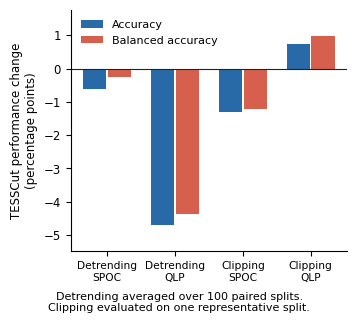

Figure 14: /data/projects/TESS_Research_Publication/results/publication_figures/detrending_controlled_test_deltas.pdf


In [28]:
from pathlib import Path
import hashlib
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def export_figure_14(project_root=None, output_dir=None, *, export_png=True, show=True):
    """Export the matched preprocessing comparison from corrected saved tables."""
    if project_root is None:
        project_root = globals().get("Project_Root") or os.environ.get(
            "Project_Root", "/data/projects/TESS_Research_Publication"
        )
    project_root = Path(project_root)
    results = project_root / "results"
    detrending_dir = results / "detrending"
    clipping_dir = results / "sigma_clipping"
    comparisons = ("SPOC", "QLP")
    version = "eligibility_fap_v1"
    provenance = {}

    def read_manifest(path):
        manifest = json.loads(path.read_text(encoding="utf-8"))
        if manifest.get("science_fix_version") != version:
            raise ValueError(f"{path}: expected corrected run version {version}")
        config = manifest.get("config", {})
        if config.get("fap_policy") != "periodogram_search_bounds":
            raise ValueError(f"{path}: missing corrected periodogram search policy")
        if config.get("minimum_cadences") != 100 or config.get("test_size") != 0.30:
            raise ValueError(f"{path}: unexpected eligibility or test split settings")
        provenance[str(path.resolve())] = hashlib.sha256(path.read_bytes()).hexdigest()
        return manifest

    def recorded_hash(manifest, group, filename):
        # Match the producer's uniquely named file, including when results
        # have been copied to a different project root for publication.
        hashes = [
            digest for name, digest in manifest.get(group, {}).items()
            if Path(name).name == filename
        ]
        if len(hashes) != 1:
            raise ValueError(f"Expected one manifest {group} hash for {filename}")
        return hashes[0]

    def read_table(path, manifest=None):
        digest = hashlib.sha256(path.read_bytes()).hexdigest()
        if manifest is not None and digest != recorded_hash(manifest, "outputs", path.name):
            raise ValueError(f"{path}: table does not match the corrected run manifest")
        provenance[str(path.resolve())] = digest
        return pd.read_csv(path, float_precision="round_trip")

    detrending_manifest = read_manifest(detrending_dir / "run_manifest.json")
    detrending_config = detrending_manifest["config"]
    if detrending_config.get("split_seeds") != list(range(42, 142)):
        raise ValueError("Figure 14 requires detrending results for split seeds 42 through 141")
    features = detrending_config.get("features", [])
    if (len(features) != 39 or len(set(features)) != 39
            or "LsFalseAlarmProbability" not in features or "ProvenanceScore" in features):
        raise ValueError("Detrending results do not use the frozen 39-predictor schema")

    detrending = read_table(detrending_dir / "summary.csv", detrending_manifest)
    detrending = detrending.set_index(["Comparison", "Metric"])
    detrending_keys = {(name, metric) for name in comparisons
                       for metric in ("Accuracy", "BalancedAccuracy", "MacroF1")}
    if not detrending.index.is_unique or set(detrending.index) != detrending_keys:
        raise ValueError("Detrending summary must have one row per comparison and metric")
    if not detrending["Splits"].eq(100).all():
        raise ValueError("Each detrending result must summarize 100 paired splits")
    delta_columns = ["MeanGapBefore", "MeanGapAfter", "MeanImprovement"]
    detrending_values = detrending[delta_columns].to_numpy(dtype=float)
    if (not np.isfinite(detrending_values).all()
            or not np.allclose(detrending_values[:, 0] - detrending_values[:, 1],
                               detrending_values[:, 2], atol=1e-12, rtol=0)):
        raise ValueError("Detrending improvements must equal the decreases in mean gap")

    clipping = read_table(clipping_dir / "sigma_clip_canonical_controlled_test_deltas.csv")
    clipping = clipping.set_index("Comparison")
    if not clipping.index.is_unique or set(clipping.index) != {f"{name} vs TESSCut" for name in comparisons}:
        raise ValueError("Clipping summary must have one SPOC and one QLP comparison")
    metric_columns = ["AccuracyBefore", "AccuracyAfter", "AccuracyDelta",
                      "BalancedAccuracyBefore", "BalancedAccuracyAfter", "BalancedAccuracyDelta"]
    for name in comparisons:
        prefix = f"{name.lower()}_tesscut_sigma_clip"
        clip_manifest = read_manifest(clipping_dir / f"{prefix}_run_manifest.json")
        clip_config = clip_manifest["config"]
        if clip_config.get("split_seed") != 42 or clip_config.get("features") != features:
            raise ValueError(f"{name}: expected corrected seed-42 clipping and shared predictors")
        baseline = f"{name}_TESSCut_features_QC.parquet"
        if recorded_hash(clip_manifest, "inputs", baseline) != recorded_hash(detrending_manifest, "inputs", baseline):
            raise ValueError(f"{name}: interventions used different baseline feature files")
        det_count = detrending_config.get("matched_counts", {}).get(name)
        if (not isinstance(det_count, int) or det_count <= 0
                or clip_config.get("analysis_stars") != det_count):
            raise ValueError(f"{name}: intervention cohort sizes differ or are missing")

        per_case = read_table(clipping_dir / f"{prefix}_sigma_clip_test_deltas.csv", clip_manifest)
        label = f"{name} vs TESSCut"
        if per_case["Comparison"].tolist() != [label]:
            raise ValueError(f"{name}: invalid per-comparison clipping delta table")
        verified = per_case[metric_columns].to_numpy(dtype=float)[0]
        combined = clipping.loc[label, metric_columns].to_numpy(dtype=float)
        if not np.isfinite(verified).all() or not np.allclose(verified, combined, atol=1e-12, rtol=0):
            raise ValueError(f"{name}: combined clipping CSV differs from its verified results")
        for before, after, delta in verified.reshape(2, 3):
            if not (0 <= before <= 1 and 0 <= after <= 1
                    and np.isclose(after - before, delta, atol=1e-12, rtol=0)):
                raise ValueError(f"{name}: clipping delta must equal after minus before")

    values = 100 * np.array([
        [detrending.loc[(name, metric), "MeanImprovement"]
         for metric in ("Accuracy", "BalancedAccuracy")] for name in comparisons
    ] + [
        clipping.loc[f"{name} vs TESSCut", ["AccuracyDelta", "BalancedAccuracyDelta"]]
        .to_numpy(dtype=float) for name in comparisons
    ], dtype=float)
    labels = ["Detrending\nSPOC", "Detrending\nQLP", "Clipping\nSPOC", "Clipping\nQLP"]
    output_dir = Path(output_dir) if output_dir is not None else results / "publication_figures"
    output_dir.mkdir(parents=True, exist_ok=True)
    stem = "detrending_controlled_test_deltas"
    pdf_path = output_dir / f"{stem}.pdf"
    png_path = output_dir / f"{stem}.png"
    with plt.rc_context({"font.size": 8.5, "xtick.labelsize": 7.7, "legend.fontsize": 8,
                         "pdf.fonttype": 42, "ps.fonttype": 42}):
        fig, ax = plt.subplots(figsize=(3.5, 3.35))
        try:
            x = np.arange(len(labels))
            ax.bar(x - 0.18, values[:, 0], width=0.34, color="#2869a7", label="Accuracy")
            ax.bar(x + 0.18, values[:, 1], width=0.34, color="#d6604d", label="Balanced accuracy")
            ax.axhline(0, color="#222222", linewidth=0.8)
            ax.set_xticks(x, labels)
            ax.set_ylabel("TESSCut performance change\n(percentage points)")
            ax.spines["top"].set_visible(False)
            ax.spines["right"].set_visible(False)
            ax.legend(loc="upper left", frameon=False)
            ax.margins(y=0.14)
            fig.subplots_adjust(left=0.19, right=0.98, bottom=0.24, top=0.96)
            fig.text(0.5, 0.055, "Detrending averaged over 100 paired splits.\nClipping evaluated on one representative split.",
                     ha="center", va="bottom", fontsize=8)
            fig.savefig(pdf_path, metadata={"Title": "Matched TESSCut preprocessing performance changes"})
            if export_png:
                fig.savefig(png_path, dpi=600)
            if show:
                plt.show()
        finally:
            plt.close(fig)

    output_files = [pdf_path, png_path] if export_png else [pdf_path]
    record = {
        "figure": 14,
        "science_fix_version": version,
        "sources_sha256": provenance,
        "metrics": ["Accuracy", "Balanced accuracy"],
        "groups": [label.replace("\n", " ") for label in labels],
        "values_percentage_points": values.tolist(),
        "outputs_sha256": {
            str(path.resolve()): hashlib.sha256(path.read_bytes()).hexdigest()
            for path in output_files
        },
        "png_dpi": 600 if export_png else None,
    }
    (output_dir / f"{stem}_source.json").write_text(
        json.dumps(record, indent=2, allow_nan=False) + "\n", encoding="utf-8"
    )
    print(f"Figure 14: {pdf_path}")
    return record


figure_14_export = export_figure_14(
    output_dir=globals().get("PUBLICATION_FIGURE_OUTPUT_DIR"),
    export_png=True,
)
